# Etapa 10c · Encoder pré-treinado: o XLM-R em inteiros de 8 bits

| | |
|---|---|
| **Pergunta** | Quanto o XLM-R encolhe e acelera em inteiros de 8 bits, e a qualidade se conserva? |
| **Entrada** | `entregas/10b_encoder_poda/decisao.json` (as variantes podadas que seguem, de cada modelo de partida, e onde estão), `entregas/10a_encoder/` (os mesmos modelos sem poda), `entregas/01_dados/` (os pedidos) e o que os comandos de `especialista/experimentos/etapa10c.py` gravaram. |
| **Entrega** | `entregas/10c_encoder_quantizacao/`: cada modelo exportado e quantizado (3 sementes), a comparação pareada de cada forma de quantizar com o mesmo modelo em 32 bits, tamanho e latência medidos, e o `decisao.json` com o modelo final do caminho do encoder pré-treinado. |
| **Pronto quando** | (1) cada modelo que a Etapa 10b marcou foi quantizado nas 3 sementes, sem nenhum treino; (2) o ONNX de 32 bits dá as mesmas respostas do PyTorch em todos os pedidos de `dev` e do teste; (3) os pesos podados continuam em zero depois de quantizar; (4) cada forma tem comparação pareada, com intervalo de 95%, contra o mesmo modelo em 32 bits, em `dev` e no teste; (5) o tamanho foi medido em arquivos gravados e a latência no protocolo da régua, com a máquina quieta; (6) a forma final saiu de `dev`, pela regra escrita antes, e o treino ciente de quantização só entra se a regra mandar; (7) os sistemas entregues reproduzem as respostas do teste. |

**O que muda em relação à Etapa 8.** A Etapa 8 quantizou a rede do zero, de 4,9 milhões de parâmetros. Aqui a rede é o XLM-R base ajustado na Etapa 10a: 278 milhões de parâmetros, 12 camadas, e uma tabela de 250.002 subtokens que é 69% do modelo. As regras e as formas de quantizar são as mesmas, e o código da regra é o mesmo (`etapa8.escolher_forma`). O que é novo é o tamanho do problema: mais camadas por onde o erro de arredondamento passa, e multiplicações grandes o bastante para a conta com inteiros pesar na latência.

**Artigos de apoio**

- O esquema de quantização (escala e ponto zero) e a conta só com inteiros: Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference* ([arXiv 1712.05877](https://arxiv.org/abs/1712.05877)).
- Um BERT em 8 bits, o que quantizar e o que deixar em 32 bits: Zafrir et al., *Q8BERT: Quantized 8Bit BERT* ([arXiv 1910.06188](https://arxiv.org/abs/1910.06188)).
- Por que as ativações de um Transformer são difíceis de quantizar com faixa fixa: Bondarenko et al., *Understanding and Overcoming the Challenges of Efficient Transformer Quantization* ([arXiv 2109.12948](https://arxiv.org/abs/2109.12948)).
- As formas de quantizar, lado a lado (dinâmica, estática, com treino): Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference* ([arXiv 2103.13630](https://arxiv.org/abs/2103.13630)).
- Podar, quantizar e, por fim, codificar o arquivo: Han et al., *Deep Compression* ([arXiv 1510.00149](https://arxiv.org/abs/1510.00149)).
- O encoder e as duas cabeças: Conneau et al., XLM-R ([arXiv 1911.02116](https://arxiv.org/abs/1911.02116)); Chen et al., JointBERT ([arXiv 1902.10909](https://arxiv.org/abs/1902.10909)).
- O que cada forma quantiza no ONNX Runtime: a documentação da ferramenta, [Quantize ONNX models](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html).

**Roteiro**

1. Os modelos que chegam da poda
2. O que ficou decidido antes de medir
3. A exportação: a mesma rede, fora do PyTorch
4. O que a quantização faz com os pesos
5. Qualidade: cada forma contra o mesmo modelo em 32 bits
6. Tamanho
7. Latência
8. A forma final de cada modelo
9. Entrega
10. Resposta

In [1]:
import gzip
import hashlib
import json
import os
import shutil
from datetime import date
from importlib import metadata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import carregar_previsoes, ouro
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.compressao import exportacao_encoder, quantizacao
from especialista.compressao.sistema_encoder_onnx import FICHA, REDE, REDE_COMPACTADA, TOKENIZADOR, TOKENIZADOR_COMPACTADO, SistemaEncoderOnnx
from especialista.dados import massive
from especialista.experimentos import etapa10c

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("10c_encoder_quantizacao")
SEMENTES = etapa10c.SEMENTES
REFERENCIA, CANDIDATAS, FORMAS = etapa10c.REFERENCIA, etapa10c.CANDIDATAS, etapa10c.FORMAS
NOME_DA_FORMA = etapa10c.NOMES
LIMITE = etapa10c.LIMITE_DO_PLANO

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
ouro_dev, ouro_teste = ouro(dev), ouro(teste)
gabarito = {"dev": ouro_dev, "test": ouro_teste}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras
da_10a = json.loads((ENTREGAS / etapa10c.DECISAO_DO_ENCODER).read_text(encoding="utf-8"))
da_8 = json.loads((ENTREGAS / "08_quantizacao" / "decisao.json").read_text(encoding="utf-8"))["final"]   # o modelo final do caminho do zero


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    """Vírgula decimal e ponto de milhar: 1127.5 vira "1.127,5"."""
    return f"{x:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def mb(x, casas=1):
    return num(x / 1e6, casas)


def com_intervalo(linha, casas=1):
    return f"{dif(linha['diferenca'], casas)} ({dif(linha['ic_min'], casas)} a {dif(linha['ic_max'], casas)})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def acaso(achadas, comparacoes):
    """Com muitas comparações a 95%, algumas saem do zero sem que haja diferença: a frase que lembra disso."""
    if not achadas:
        return ""
    return f" {'É 1' if achadas == 1 else f'São {achadas}'} em {comparacoes} comparações; com intervalos de 95%, cerca de {num(0.05 * comparacoes, 1)} sairia do zero só por acaso."


def trio(linha, coluna_do_valor="diferenca"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * linha[c] for c in (coluna_do_valor, "ic_min", "ic_max"))


def diferencas(dados, titulo, eixo_x, limite=None, casas=2):
    """`visual.diferencas_com_intervalo`, com o número das diferenças negativas à esquerda da barra e, se pedido, a linha do limite."""
    fig, ax = visual.diferencas_com_intervalo(dados, titulo, eixo_x)
    for anotacao, (valor, minimo, maximo) in zip(ax.texts, dados.values()):
        anotacao.set_text(f"{valor:+.{casas}f}".replace(".", ",").replace("-", "−"))
        if valor < 0:
            anotacao.xy = (minimo, anotacao.xy[1])
            anotacao.set_position((-7, 0))
            anotacao.set_ha("right")
    if limite is not None:
        ax.axvline(limite, color=visual.TINTA_SUAVE, linewidth=1.0, linestyle=(0, (4, 3)), zorder=0.6)
        ax.annotate("limite do plano", (limite, -0.5), xytext=(4, -10), textcoords="offset points", fontsize=8.5, color=visual.TINTA_SECUNDARIA)
        ax.set_xlim(min(ax.get_xlim()[0], limite - 0.25), ax.get_xlim()[1])
    return fig, ax

## 1. Os modelos que chegam da poda

A Etapa 10b deixou, para cada modelo de partida (o aluno principal, o teto e o outro aluno), até duas variantes podadas:

- a **principal**, a de menor arquivo: um XLM-R menor (tabela de subtokens com menos linhas, menos camadas, ou as duas coisas);
- a **secundária**, a melhor de **pesos soltos**: a rede do mesmo tamanho, com parte dos pesos das matrizes do corpo em zero.

Aqui cada uma é quantizada, e também o mesmo modelo **sem poda**. A linha sem poda diz quanto a quantização custa sozinha; as outras, se a poda muda esse custo.

A quantização não treina nada. As execuções rodam fora do notebook, na CPU (`uv run python -m especialista.experimentos.etapa10c quantizar --tudo`), e ficam em `data/execucoes/10c_encoder_quantizacao/`. Aqui elas só são lidas.

In [2]:
tem_decisao_da_poda = (ENTREGAS / etapa10c.DECISAO_DA_PODA).exists()
fichas = etapa10c.modelos_a_quantizar()
faltam = etapa10c.faltam()
assert not faltam, "Faltam execuções. Rode: uv run python -m especialista.experimentos.etapa10c quantizar --tudo. Faltam: " + ", ".join(f"{m} {v} {s}" for m, v, s in faltam)
exe = {chave: [etapa10c.carregar(*chave, s) for s in SEMENTES] for chave in fichas}
lat = {chave: etapa10c.carregar_latencia(*chave) for chave in fichas}
assert all(l is not None for l in lat.values()), "Falta medir a latência, com a máquina quieta: uv run python -m especialista.experimentos.etapa10c latencia"

CHAVES = list(fichas)
MODELOS = list(dict.fromkeys(m for m, _ in CHAVES))
FINAL = next((chave for chave in CHAVES if fichas[chave]["final"]), None)                  # o que a Etapa 10b marcou como principal deste caminho
PRINCIPAL = FINAL[0] if FINAL else MODELOS[0]                                             # o modelo de partida principal
MOSTRA = FINAL or (PRINCIPAL, "sem_poda")                                                 # o modelo dos exemplos e dos gráficos
SEM_PODA = (PRINCIPAL, "sem_poda")
PAPEL = {"sem_poda": "sem poda", "principal": "poda principal (menor arquivo)", "secundaria": "poda secundária (pesos soltos)"}
CURTO = {chave: fichas[chave]["curto"] for chave in CHAVES}
meta0 = {chave: exe[chave][0]["meta"] for chave in CHAVES}                                  # tamanhos e contagens: semente 0


def grupo(chave, forma, particao):
    """As respostas das 3 sementes de um modelo, numa forma, numa partição."""
    return [e["previsoes"][forma][particao] for e in exe[chave]]


# O que está gravado saiu destes modelos? Duas conferências:
# (a) cada execução partiu da pasta que a decisão aponta;
# (b) as respostas em PyTorch refeitas aqui na CPU são as que as Etapas 10a e 10b entregaram (calculadas na placa de vídeo, em 32 bits).
#     Entre CPU e placa de vídeo, um empate decidido na sétima casa decimal pode cair para o outro lado: por isso a conta é "quantas iguais".
relativo = lambda caminho: str(caminho.relative_to(RAIZ)) if caminho.is_relative_to(RAIZ) else str(caminho)
mesma_pasta = all(e["meta"]["de_partida"] == relativo(fichas[chave]["pastas"][s]) for chave in CHAVES for s, e in zip(SEMENTES, exe[chave]))


def entregue(chave, semente, particao):
    """As respostas que a etapa anterior entregou para este modelo (None se ela não entregou o arquivo)."""
    m, v = chave
    arquivo = (ENTREGAS / "10a_encoder" / "previsoes" / f"{m}_semente_{semente}_{particao}.parquet" if v == "sem_poda"
               else ENTREGAS / "10b_encoder_poda" / "previsoes" / f"{m}__{v}_semente_{semente}_{particao}.parquet")
    return carregar_previsoes(arquivo)[1] if arquivo.exists() else None


iguais_as_entregues, comparadas = 0, 0
for chave in CHAVES:
    for s, e in zip(SEMENTES, exe[chave]):
        for particao in ("dev", "test"):
            anteriores = entregue(chave, s, particao)
            if anteriores is not None:
                iguais_as_entregues += sum(a == b for a, b in zip(anteriores, e["previsoes"][REFERENCIA][particao], strict=True))
                comparadas += len(anteriores)
origem_confere = bool(mesma_pasta and comparadas > 0 and iguais_as_entregues / comparadas >= 0.999)
print("Cada execução partiu da pasta que a decisão aponta:", "sim" if mesma_pasta else "NÃO: quantize de novo")
print(f"Respostas em PyTorch na CPU iguais às entregues pelas Etapas 10a e 10b (placa de vídeo): {n(iguais_as_entregues)} de {n(comparadas)}")

pd.DataFrame([
    {
        "modelo": fichas[chave]["nome"], "papel": PAPEL[fichas[chave]["papel"]], "parâmetros": n(meta0[chave]["parametros"]),
        "linhas da tabela de subtokens": n(meta0[chave]["linhas_da_tabela"]), "camadas": meta0[chave]["camadas"],
        "pesos soltos em zero (matrizes do corpo)": pts(meta0[chave]["pesos_podaveis"]["esparsidade"]) + "%",
        "tamanho em 32 bits (MB)": mb(meta0[chave]["formas"][REFERENCIA]["bytes"]),
        "é o principal deste caminho": "sim" if chave == FINAL else "",
    }
    for chave in CHAVES
]).set_index("modelo")

Cada execução partiu da pasta que a decisão aponta: sim
Respostas em PyTorch na CPU iguais às entregues pelas Etapas 10a e 10b (placa de vídeo): 135.189 de 135.189


,papel,parâmetros,linhas da tabela de subtokens,camadas,pesos soltos em zero (matrizes do corpo),tamanho em 32 bits (MB),é o principal deste caminho
modelo,,,,,,,
"Aluno A (rótulos do Claude Haiku 5.5), sem poda",sem poda,277.584.555,250.002,12,"0,0%","1.127,5",
"Aluno A (rótulos do Claude Haiku 5.5), vocabulário do treino",poda principal (menor arquivo),89.573.547,5.196,12,"0,0%","359,0",sim
"Aluno A (rótulos do Claude Haiku 5.5), magnitude, 70% gradual",poda secundária (pesos soltos),277.584.555,250.002,12,"70,0%","1.127,5",
"Teto (rótulos humanos), sem poda",sem poda,277.584.555,250.002,12,"0,0%","1.127,5",
"Teto (rótulos humanos), vocabulário do treino",poda principal (menor arquivo),89.573.547,5.196,12,"0,0%","359,0",
"Teto (rótulos humanos), magnitude, 50% de uma vez",poda secundária (pesos soltos),277.584.555,250.002,12,"50,0%","1.127,5",
"Aluno B2 (logits do Qwen3-8B), sem poda",sem poda,277.584.555,250.002,12,"0,0%","1.127,5",
"Aluno B2 (logits do Qwen3-8B), vocabulário do treino",poda principal (menor arquivo),89.573.547,5.196,12,"0,0%","359,0",
"Aluno B2 (logits do Qwen3-8B), magnitude, 70% gradual",poda secundária (pesos soltos),277.584.555,250.002,12,"70,0%","1.127,5",


## 2. O que ficou decidido antes de medir

São as decisões da Etapa 8, sem mudança, escritas no texto de `experimentos/etapa10c.py` antes de medir os modelos desta etapa. O código da regra é o mesmo da Etapa 8 (`etapa8.escolher_forma`).

**1. Quantização pós-treino, com o ONNX Runtime.** O modelo ajustado é convertido sem nenhum passo de treino. Para isso ele sai do PyTorch: é exportado para ONNX, um formato de arquivo que o ONNX Runtime executa.

**2. O que entra no arquivo exportado.** Um pedido passa por três trechos; só o segundo vira ONNX.

| Trecho | Onde roda | Por quê |
|---|---|---|
| A. Texto para subtokens, e a posição do primeiro subtoken de cada palavra | pacote `tokenizers`, com o tokenizador do próprio modelo | É consulta a um vocabulário, não é conta de rede |
| B a D. Dos subtokens às pontuações de cada intenção e de cada tag | **ONNX** | É onde estão os pesos e as multiplicações |
| Montar a resposta (a intenção e a tag mais pontuadas) | Python | Não há CRF neste caminho (Chen et al.) |

O sistema exportado não usa PyTorch nem a biblioteca `transformers` (um teste confere). A latência é medida no sistema inteiro, com os três trechos.

**3. A exportação não pode mudar as respostas.** O ONNX de 32 bits tem de responder igual ao PyTorch em todos os pedidos de `dev` e do teste. Só depois disso a diferença de um modelo de 8 bits pode ser atribuída à quantização.

**4. O que é quantizado.** O recorte de Zafrir et al. (Q8BERT): as tabelas de entrada e as camadas lineares vão para 8 bits, com um degrau por tensor (Jacob et al.).

| Parte | Em 8 bits? | Como |
|---|---|---|
| Tabela de subtokens e tabela de posições | sim | um degrau para a tabela inteira, inteiros sem sinal |
| Matrizes: as 6 de cada camada do corpo (consulta, chave, valor e saída da atenção; as duas da rede densa) e as das duas cabeças | sim | um degrau por matriz, inteiros com sinal, faixa simétrica |
| Vieses e normalizações de camada | não | são poucos números, somados depois da multiplicação |
| Produtos da atenção entre duas ativações, softmax, GELU, somas | não | não têm pesos |

**5. Duas formas de tratar as ativações**, que são os valores que passam pela rede. A documentação do ONNX Runtime as descreve assim: na **dinâmica**, a escala e o ponto zero das ativações são calculados na hora, em cada passada; na **estática**, são calculados antes, num conjunto de calibração, e são os mesmos em toda passada. Na estática, a saída de cada multiplicação também é arredondada para 8 bits. Os pesos são quantizados do mesmo jeito nas duas.

A mesma documentação recomenda a dinâmica para modelos baseados em Transformer, e Bondarenko et al. explicam o motivo: as ativações de um Transformer têm faixas muito diferentes de uma dimensão para outra e de um pedido para outro, e uma faixa fixa serve mal. Na rede do zero (Etapa 8) as duas passaram. Aqui as duas são medidas de novo, com a mesma regra.

**6. O conjunto de calibração da estática:** 512 pedidos do treino, sorteados uma vez, sem rótulo, passados um por vez. São os mesmos da Etapa 8, para todos os modelos. Nenhum pedido de `dev` ou do teste entra.

**7. Um pedido por vez.** Toda resposta desta etapa é calculada com um pedido por passada, como no protocolo de latência.

**8. Duas formas a mais, só para ver onde está o custo:** 8 bits só nas tabelas de entrada e 8 bits só nas matrizes. Respondem só em `dev` e não concorrem a modelo final.

**9. As medidas.** Para cada modelo e cada forma: as 4 métricas da régua com intervalo de 95%, na média de 3 sementes; a diferença pareada para **o mesmo modelo em 32 bits, no PyTorch** (`qualidade.comparar_grupos`); o tamanho dos arquivos gravados, com a rede separada do tokenizador; e a latência no protocolo da Etapa 2 (uma consulta por vez, 1 thread, do texto à resposta, 1.024 consultas), em 5 rodadas alternadas entre os sistemas, com a máquina quieta.

**10. Os zeros da poda.** Um peso podado tem de continuar zero depois de quantizar; isso é conferido peso por peso. E um zero de 8 bits ocupa um byte, como qualquer outro peso: para o modelo de pesos soltos, mede-se também o arquivo depois de um compressor comum (gzip), que é onde os zeros contam (Han et al.).

**11. A regra do treino ciente de quantização (QAT), que é a do plano do projeto.** O QAT só entra se o F1 de entidades cair **mais de 1 ponto** com a quantização pós-treino, em `dev`, em relação ao mesmo modelo em 32 bits.

**12. A regra da forma final**, aplicada a cada modelo, em `dev`, com os rótulos humanos:

1. **Passa** a forma cujo F1 de entidades cai no máximo 1 ponto (diferença pareada, média das 3 sementes).
2. Se nenhuma passa, entra o QAT para esse modelo. É o único caso.
3. Se só uma passa, é ela.
4. Se as duas passam, sai a que for distinguivelmente pior que a outra em exact match (intervalo de 95% todo de um lado do zero). Se nenhuma sair, fica a estática só se a latência mediana dela for menor que a da dinâmica em todas as 5 rodadas; senão fica a dinâmica, que é a mais simples: não precisa de calibração.

**13. O modelo final deste caminho** é o aluno A na variante que a Etapa 10b marcou como principal, na forma que a regra escolher para ela.

## 3. A exportação: a mesma rede, fora do PyTorch

O grafo é montado operação por operação em `compressao/exportacao_encoder.py`, com os nomes que os pesos têm no PyTorch. O mesmo código serve para o modelo inteiro, para o de vocabulário cortado (a tabela tem menos linhas, e o tokenizador reduzido vai junto) e para o de menos camadas. Abaixo, as operações que há em cada arquivo de um dos modelos, e a conferência da decisão 3 em todos eles.

In [3]:
QUE_OPERACOES = {
    "MatMul": "multiplicação de matrizes em 32 bits", "MatMulInteger": "multiplicação de matrizes com inteiros de 8 bits",
    "DynamicQuantizeLinear": "mede a faixa da ativação na hora e arredonda para 8 bits", "QuantizeLinear": "arredonda para 8 bits com faixa gravada",
    "DequantizeLinear": "volta de 8 bits para número real", "Gather": "busca linhas numa tabela", "LayerNormalization": "normalização de camada",
    "Softmax": "softmax da atenção", "Erf": "a função erro da GELU",
}
operacoes = pd.DataFrame({NOME_DA_FORMA[forma]: meta0[MOSTRA]["formas"][forma]["operacoes_do_grafo"] for forma in ("fp32", *CANDIDATAS)}).fillna(0).astype(int)
print(f"{CURTO[MOSTRA]}, semente 0: o grafo de 32 bits tem {n(operacoes[NOME_DA_FORMA['fp32']].sum())} operações de {int((operacoes[NOME_DA_FORMA['fp32']] > 0).sum())} tipos.")
display(operacoes.loc[[o for o in QUE_OPERACOES if o in operacoes.index]].assign(**{"o que é": lambda t: [QUE_OPERACOES[o] for o in t.index]}))

iguais = pd.DataFrame([
    {
        "modelo": CURTO[chave],
        **{f"{particao}: pedidos × sementes": n(sum(e["meta"]["pedidos"][particao] for e in exe[chave])) for particao in ("dev", "test")},
        **{f"{particao}: respostas iguais às do PyTorch": n(sum(e["meta"]["formas"]["fp32"][f"iguais_ao_pytorch_{particao}"] for e in exe[chave])) for particao in ("dev", "test")},
    }
    for chave in CHAVES
]).set_index("modelo")
total_de_respostas = sum(e["meta"]["pedidos"][p] for chave in CHAVES for e in exe[chave] for p in ("dev", "test"))
respostas_iguais = sum(e["meta"]["formas"]["fp32"][f"iguais_ao_pytorch_{p}"] for chave in CHAVES for e in exe[chave] for p in ("dev", "test"))
exportacao_confere = respostas_iguais == total_de_respostas
display(iguais)
g = operacoes
display(Markdown(f"""
**Leitura.**

- O ONNX de 32 bits deu a mesma resposta do PyTorch em {n(respostas_iguais)} de {n(total_de_respostas)} respostas ({len(CHAVES)} modelos × {len(SEMENTES)} sementes × `dev` e teste). {"A exportação não mudou nenhuma resposta: daqui em diante, o que mudar vem da quantização." if exportacao_confere else "**A exportação mudou respostas: a etapa não pode seguir assim.**"}
- **O que cada forma converte** ({CURTO[MOSTRA]}). No grafo de 32 bits há {n(g.loc['MatMul', NOME_DA_FORMA['fp32']])} multiplicações de matrizes. Na dinâmica, {n(g.loc['MatMulInteger', NOME_DA_FORMA['dinamica']])} delas passam a ser feitas com inteiros de 8 bits; as {n(g.loc['MatMul', NOME_DA_FORMA['dinamica']])} que continuam em 32 bits são os dois produtos da atenção de cada camada, entre duas ativações. Na estática, as mesmas multiplicações ficam cercadas por operações de arredondar e de voltar ({n(g.loc['QuantizeLinear', NOME_DA_FORMA['estatica']])} e {n(g.loc['DequantizeLinear', NOME_DA_FORMA['estatica']])}), com a faixa gravada; o ONNX Runtime as junta numa conta com inteiros ao carregar.
- **O que não muda em nenhuma das duas:** as {n(g.loc['LayerNormalization', NOME_DA_FORMA['dinamica']])} normalizações de camada, os {n(g.loc['Softmax', NOME_DA_FORMA['dinamica']])} softmax e as {n(g.loc['Erf', NOME_DA_FORMA['dinamica']])} GELU continuam em 32 bits.
"""))

Aluno A, vocabulário do treino, semente 0: o grafo de 32 bits tem 432 operações de 18 tipos.


,"ONNX, 32 bits","INT8, quantização dinâmica","INT8, quantização estática",o que é
MatMul,98,24,98,multiplicação de matrizes em 32 bits
MatMulInteger,0,74,0,multiplicação de matrizes com inteiros de 8 bits
DynamicQuantizeLinear,0,50,0,mede a faixa da ativação na hora e arredonda para 8 bits
QuantizeLinear,0,0,126,arredonda para 8 bits com faixa gravada
DequantizeLinear,0,2,202,volta de 8 bits para número real
Gather,3,3,3,busca linhas numa tabela
LayerNormalization,25,25,25,normalização de camada
Softmax,12,12,12,softmax da atenção
Erf,12,12,12,a função erro da GELU


,dev: pedidos × sementes,test: pedidos × sementes,dev: respostas iguais às do PyTorch,test: respostas iguais às do PyTorch
modelo,,,,
"Aluno A, sem poda",6.099,8.922,6.099,8.922
"Aluno A, vocabulário do treino",6.099,8.922,6.099,8.922
"Aluno A, gradual 70%",6.099,8.922,6.099,8.922
"Teto, sem poda",6.099,8.922,6.099,8.922
"Teto, vocabulário do treino",6.099,8.922,6.099,8.922
"Teto, magnitude 50%",6.099,8.922,6.099,8.922
"Aluno B2, sem poda",6.099,8.922,6.099,8.922
"Aluno B2, vocabulário do treino",6.099,8.922,6.099,8.922
"Aluno B2, gradual 70%",6.099,8.922,6.099,8.922



**Leitura.**

- O ONNX de 32 bits deu a mesma resposta do PyTorch em 135.189 de 135.189 respostas (9 modelos × 3 sementes × `dev` e teste). A exportação não mudou nenhuma resposta: daqui em diante, o que mudar vem da quantização.
- **O que cada forma converte** (Aluno A, vocabulário do treino). No grafo de 32 bits há 98 multiplicações de matrizes. Na dinâmica, 74 delas passam a ser feitas com inteiros de 8 bits; as 24 que continuam em 32 bits são os dois produtos da atenção de cada camada, entre duas ativações. Na estática, as mesmas multiplicações ficam cercadas por operações de arredondar e de voltar (126 e 202), com a faixa gravada; o ONNX Runtime as junta numa conta com inteiros ao carregar.
- **O que não muda em nenhuma das duas:** as 25 normalizações de camada, os 12 softmax e as 12 GELU continuam em 32 bits.


## 4. O que a quantização faz com os pesos

Primeiro o que muda no arquivo, parte por parte. Depois o erro de arredondamento de cada tipo de tensor e a conferência dos zeros.

Aluno A, vocabulário do treino, semente 0, INT8, quantização dinâmica


,tensores,números,MB em 32 bits,MB em 8 bits,parte do arquivo de 32 bits
parte,,,,,
Tabela de subtokens,1,3.990.528,"15,96","3,99","4,5%"
Tabela de posições,1,394.752,"1,58","0,39","0,4%"
Matrizes do corpo (6 por camada),72,84.934.656,"339,74","84,93","94,8%"
Matrizes das duas cabeças,2,131.328,"0,53","0,13","0,1%"
"O que fica em 32 bits (vieses, normalizações)",125,122.283,"0,49","0,49","0,1%"


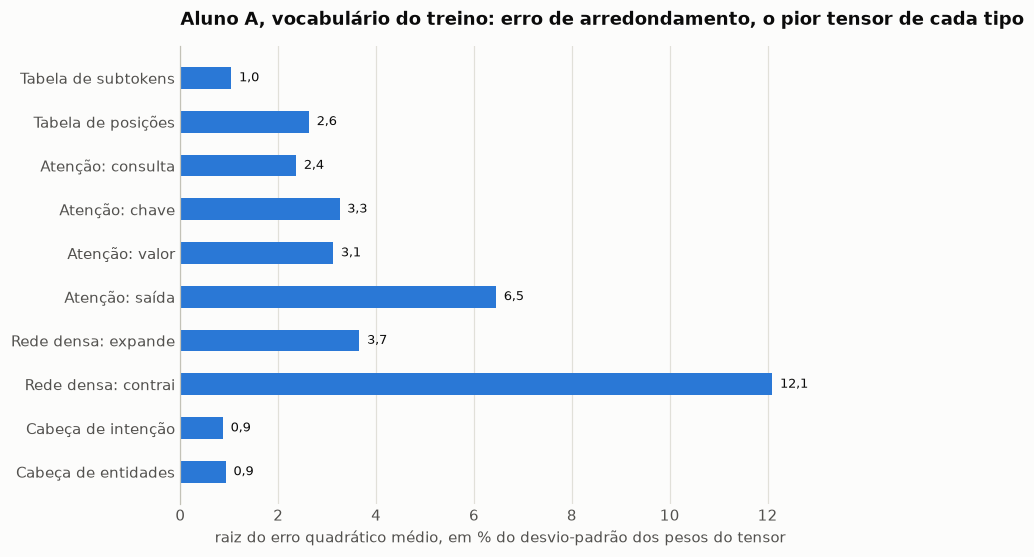

Zeros antes e depois de quantizar, somados nas 3 sementes (só nos tensores quantizados)


pesos em zero antes  \
modelo                          forma                                            
Aluno A, sem poda               INT8, quantização dinâmica               2.400   
                                INT8, quantização estática               2.400   
Aluno A, vocabulário do treino  INT8, quantização dinâmica               2.304   
                                INT8, quantização estática               2.304   
Aluno A, gradual 70%            INT8, quantização dinâmica         178.365.192   
                                INT8, quantização estática         178.365.192   
Teto, sem poda                  INT8, quantização dinâmica               2.400   
                                INT8, quantização estática               2.400   
Teto, vocabulário do treino     INT8, quantização dinâmica               2.304   
                                INT8, quantização estática               2.304   
Teto, magnitude 50%             INT8, quantização dinâmica         127.404.384   
                                INT8, quantização estática         127.404.384   
Aluno B2, sem poda              INT8, quantização dinâmica               2.400   
                                INT8, quantização estática               2.400   
Aluno B2, vocabulário do treino INT8, quantização dinâmica               2.304   
                                INT8, quantização estática               2.304   
Aluno B2, gradual 70%           INT8, quantização dinâmica         178.365.192   
                                INT8, quantização estática         178.365.192   

                                                           pesos em zero depois  \
modelo                          forma                                             
Aluno A, sem poda               INT8, quantização dinâmica           39.860.273   
                                INT8, quantização estática           39.860.273   
Aluno A, vocabulário do treino  INT8, quantização dinâmica           21.732.147   
                                INT8, quantização estática           21.732.147   
Aluno A, gradual 70%            INT8, quantização dinâmica          196.845.911   
                                INT8, quantização estática          196.845.911   
Teto, sem poda                  INT8, quantização dinâmica           39.865.747   
                                INT8, quantização estática           39.865.747   
Teto, vocabulário do treino     INT8, quantização dinâmica           21.733.451   
                                INT8, quantização estática           21.733.451   
Teto, magnitude 50%             INT8, quantização dinâmica          145.914.169   
                                INT8, quantização estática          145.914.169   
Aluno B2, sem poda              INT8, quantização dinâmica           39.846.775   
                                INT8, quantização estática           39.846.775   
Aluno B2, vocabulário do treino INT8, quantização dinâmica           21.715.982   
                                INT8, quantização estática           21.715.982   
Aluno B2, gradual 70%           INT8, quantização dinâmica          196.868.140   
                                INT8, quantização estática          196.868.140   

                                                           zeros que deixaram de ser zero  
modelo                          forma                                                      
Aluno A, sem poda               INT8, quantização dinâmica                              0  
                                INT8, quantização estática                              0  
Aluno A, vocabulário do treino  INT8, quantização dinâmica                              0  
                                INT8, quantização estática                              0  
Aluno A, gradual 70%            INT8, quantização dinâmica                              0  
                                INT8, quantização estática                              0  
Teto, sem poda       

In [4]:
forma_da_mostra = "dinamica"
pasta_da_mostra = exe[MOSTRA][0]["pasta"]
pesos = quantizacao.pesos_antes_e_depois(pasta_da_mostra / "sistemas" / "fp32", pasta_da_mostra / "sistemas" / forma_da_mostra)

SUBTOKENS, POSICOES, CORPO, CABECAS, RESTO = ("Tabela de subtokens", "Tabela de posições", "Matrizes do corpo (6 por camada)", "Matrizes das duas cabeças",
                                              "O que fica em 32 bits (vieses, normalizações)")
EM_8_BITS = [SUBTOKENS, POSICOES, CORPO, CABECAS]


def parte(tensor):
    if tensor == exportacao_encoder.TABELA_DE_SUBTOKENS:
        return SUBTOKENS
    if tensor == exportacao_encoder.TABELA_DE_POSICOES:
        return POSICOES
    if pesos.loc[tensor, "tipo_depois"] not in ("int8", "uint8"):
        return RESTO
    return CABECAS if tensor.startswith(("intencao", "entidades")) else CORPO


por_parte = pesos.assign(parte=[parte(t) for t in pesos.index]).groupby("parte", sort=False).agg(
    tensores=("numeros", "size"), numeros=("numeros", "sum"), bytes_antes=("bytes_antes", "sum"), bytes_depois=("bytes_depois", "sum")).reindex([*EM_8_BITS, RESTO])
arquivos = meta0[MOSTRA]["formas"][forma_da_mostra]["arquivos"]
print(f"{CURTO[MOSTRA]}, semente 0, {NOME_DA_FORMA[forma_da_mostra]}")
display(por_parte.assign(**{
    "números": por_parte["numeros"].map(n), "MB em 32 bits": por_parte["bytes_antes"].map(lambda v: mb(v, 2)), "MB em 8 bits": por_parte["bytes_depois"].map(lambda v: mb(v, 2)),
    "parte do arquivo de 32 bits": (por_parte["bytes_antes"] / por_parte["bytes_antes"].sum()).map(lambda v: pts(v) + "%"),
})[["tensores", "números", "MB em 32 bits", "MB em 8 bits", "parte do arquivo de 32 bits"]])

# O erro de arredondamento de cada tensor, gravado pela execução (os pesos em 8 bits são os mesmos nas duas formas)
erro = pd.read_csv(pasta_da_mostra / "erro_dos_pesos.csv", index_col="tensor")
TIPOS = {
    exportacao_encoder.TABELA_DE_SUBTOKENS: "Tabela de subtokens", exportacao_encoder.TABELA_DE_POSICOES: "Tabela de posições",
    "attention.self.query.weight": "Atenção: consulta", "attention.self.key.weight": "Atenção: chave", "attention.self.value.weight": "Atenção: valor",
    "attention.output.dense.weight": "Atenção: saída", "intermediate.dense.weight": "Rede densa: expande", "output.dense.weight": "Rede densa: contrai",
    "intencao.weight": "Cabeça de intenção", "entidades.weight": "Cabeça de entidades",
}
tipo_de = lambda tensor: next(nome for fim, nome in TIPOS.items() if tensor.endswith(fim))
erro_por_tipo = erro.assign(tipo=[tipo_de(t) for t in erro.index]).groupby("tipo", sort=False)["erro_relativo"].agg(["min", "max", "size"]).reindex(list(dict.fromkeys(TIPOS.values())))
fig, ax = visual.barras_em_ordem(
    {tipo: 100 * linha["max"] for tipo, linha in erro_por_tipo.iterrows()},
    f"{CURTO[MOSTRA]}: erro de arredondamento, o pior tensor de cada tipo", "raiz do erro quadrático médio, em % do desvio-padrão dos pesos do tensor",
    formato=lambda v: num(v, 1),
)
visual.salvar(fig, PASTA, "erro_dos_pesos")
plt.show()

zeros = pd.DataFrame([
    {
        "modelo": CURTO[chave], "forma": NOME_DA_FORMA[forma],
        "pesos em zero antes": n(sum(e["meta"]["formas"][forma]["zeros_antes"] for e in exe[chave])),
        "pesos em zero depois": n(sum(e["meta"]["formas"][forma]["zeros_depois"] for e in exe[chave])),
        "zeros que deixaram de ser zero": n(sum(e["meta"]["formas"][forma]["zeros_perdidos"] for e in exe[chave])),
    }
    for chave in CHAVES for forma in CANDIDATAS
]).set_index(["modelo", "forma"])
zeros_conservados = all(e["meta"]["formas"][forma]["conservados"] for chave in CHAVES for e in exe[chave] for forma in FORMAS)
print("Zeros antes e depois de quantizar, somados nas 3 sementes (só nos tensores quantizados)")
display(zeros)

In [5]:
tabela_bytes = por_parte.loc[SUBTOKENS]
matrizes_antes, matrizes_depois = por_parte.loc[[CORPO, CABECAS], "bytes_antes"].sum(), por_parte.loc[[CORPO, CABECAS], "bytes_depois"].sum()
pior, melhor = erro["erro_relativo"].idxmax(), erro["erro_relativo"].idxmin()
com_zeros = [chave for chave in CHAVES if fichas[chave]["papel"] == "secundaria"]
erro_da_tabela = erro.loc[exportacao_encoder.TABELA_DE_SUBTOKENS]
display(Markdown(f"""
**Leitura.**

- **Onde está o tamanho.** A tabela de subtokens é {pts(tabela_bytes['bytes_antes'] / por_parte['bytes_antes'].sum())}% dos pesos do arquivo de 32 bits: {mb(tabela_bytes['bytes_antes'])} MB, que viram {mb(tabela_bytes['bytes_depois'])} MB. As matrizes vão de {mb(matrizes_antes)} para {mb(matrizes_depois)} MB. O que fica em 32 bits soma {mb(por_parte.loc[RESTO, 'bytes_antes'], 2)} MB.
- **O arquivo do sistema** tem ainda o tokenizador ({mb(arquivos[TOKENIZADOR], 2)} MB, em texto), que não encolhe com a quantização.
- **O erro de arredondamento** vai de {num(100 * erro.loc[melhor, 'erro_relativo'], 1)}% do desvio-padrão dos pesos (`{melhor}`) a {num(100 * erro.loc[pior, 'erro_relativo'], 1)}% (`{pior}`). Na tabela de subtokens é {num(100 * erro_da_tabela['erro_relativo'], 1)}%: o maior peso dela, em valor absoluto, é {num(erro_da_tabela['maior_peso'], 2)}, e o degrau, {num(erro_da_tabela['degrau'], 4)}, é o mesmo para as {n(meta0[MOSTRA]['linhas_da_tabela'])} linhas. O erro é maior onde poucos pesos muito grandes esticam a faixa: o degrau cresce para todos.
- **Os zeros.** {"Nenhum peso que era zero deixou de ser" if zeros_conservados else "**Há pesos que eram zero e deixaram de ser**"}, em nenhum modelo, semente ou forma. O número de zeros até cresce: pesos muito pequenos são arredondados para zero.{f" Nos modelos de pesos soltos ({', '.join(CURTO[c] for c in com_zeros)}), a máscara da poda sobrevive à quantização." if com_zeros else ""}
"""))


**Leitura.**

- **Onde está o tamanho.** A tabela de subtokens é 4,5% dos pesos do arquivo de 32 bits: 16,0 MB, que viram 4,0 MB. As matrizes vão de 340,3 para 85,1 MB. O que fica em 32 bits soma 0,49 MB.
- **O arquivo do sistema** tem ainda o tokenizador (0,48 MB, em texto), que não encolhe com a quantização.
- **O erro de arredondamento** vai de 0,9% do desvio-padrão dos pesos (`intencao.weight`) a 12,1% (`encoder.encoder.layer.11.output.dense.weight`). Na tabela de subtokens é 1,0%: o maior peso dela, em valor absoluto, é 1,03, e o degrau, 0,0079, é o mesmo para as 5.196 linhas. O erro é maior onde poucos pesos muito grandes esticam a faixa: o degrau cresce para todos.
- **Os zeros.** Nenhum peso que era zero deixou de ser, em nenhum modelo, semente ou forma. O número de zeros até cresce: pesos muito pequenos são arredondados para zero. Nos modelos de pesos soltos (Aluno A, gradual 70%, Teto, magnitude 50%, Aluno B2, gradual 70%), a máscara da poda sobrevive à quantização.


## 5. Qualidade: cada forma contra o mesmo modelo em 32 bits

Toda diferença abaixo é "a forma menos o mesmo modelo em 32 bits no PyTorch", pareada, na média de 3 sementes. Primeiro em `dev`, que é onde as regras decidem; o teste vem na seção 8, só para a forma escolhida.

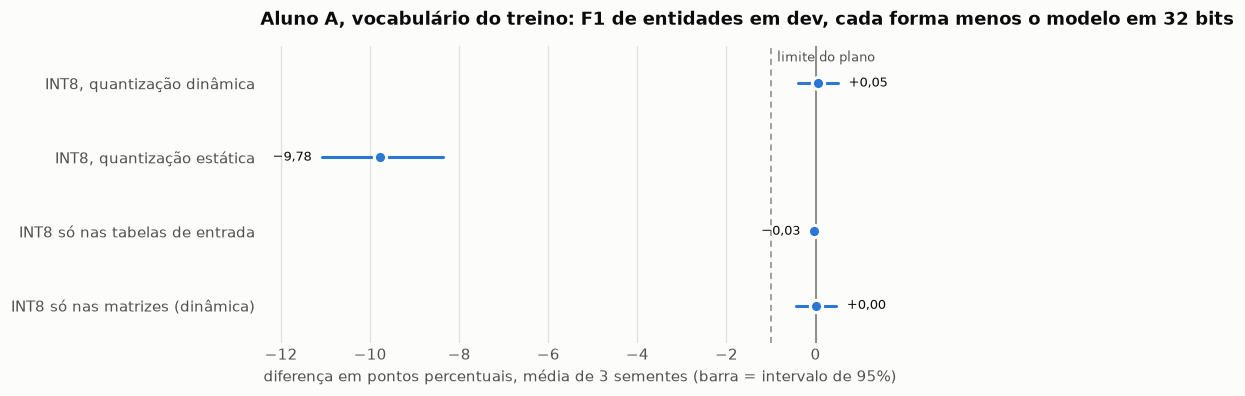

dev: diferença para o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes


Acurácia de intenção  \
modelo                          forma                                                    
Aluno A, sem poda               INT8, quantização dinâmica       −0,28 (−0,66 a +0,08)   
                                INT8, quantização estática       −5,39 (−6,38 a −4,44)   
                                INT8 só nas tabelas de entrada   +0,02 (−0,03 a +0,08)   
                                INT8 só nas matrizes (dinâmica)  −0,10 (−0,52 a +0,31)   
Aluno A, vocabulário do treino  INT8, quantização dinâmica       −0,41 (−0,79 a −0,03)   
                                INT8, quantização estática       −4,97 (−5,90 a −4,08)   
                                INT8 só nas tabelas de entrada   −0,07 (−0,15 a +0,00)   
                                INT8 só nas matrizes (dinâmica)  −0,38 (−0,72 a −0,02)   
Aluno A, gradual 70%            INT8, quantização dinâmica       −0,07 (−0,49 a +0,33)   
                                INT8, quantização estática       −1,98 (−2,84 a −1,21)   
                                INT8 só nas tabelas de entrada   −0,02 (−0,10 a +0,07)   
                                INT8 só nas matrizes (dinâmica)  −0,05 (−0,43 a +0,33)   
Teto, sem poda                  INT8, quantização dinâmica       −0,49 (−0,98 a −0,05)   
                                INT8, quantização estática       −7,95 (−8,89 a −7,02)   
                                INT8 só nas tabelas de entrada   +0,03 (−0,05 a +0,11)   
                                INT8 só nas matrizes (dinâmica)  −0,30 (−0,74 a +0,11)   
Teto, vocabulário do treino     INT8, quantização dinâmica       −0,46 (−0,95 a +0,00)   
                                INT8, quantização estática       −5,92 (−6,74 a −5,10)   
                                INT8 só nas tabelas de entrada   +0,02 (−0,07 a +0,08)   
                                INT8 só nas matrizes (dinâmica)  −0,31 (−0,75 a +0,13)   
Teto, magnitude 50%             INT8, quantização dinâmica       −0,23 (−0,69 a +0,23)   
                                INT8, quantização estática       −4,67 (−5,54 a −3,82)   
                                INT8 só nas tabelas de entrada   −0,03 (−0,11 a +0,03)   
                                INT8 só nas matrizes (dinâmica)  −0,49 (−0,92 a −0,07)   
Aluno B2, sem poda              INT8, quantização dinâmica       −0,48 (−0,92 a −0,05)   
                                INT8, quantização estática       −3,43 (−4,33 a −2,51)   
                                INT8 só nas tabelas de entrada   +0,02 (−0,03 a +0,07)   
                                INT8 só nas matrizes (dinâmica)  −0,25 (−0,64 a +0,21)   
Aluno B2, vocabulário do treino INT8, quantização dinâmica       −0,30 (−0,71 a +0,13)   
                                INT8, quantização estática       −3,23 (−4,12 a −2,34)   
                                INT8 só nas tabelas de entrada   −0,05 (−0,11 a +0,00)   
                                INT8 só nas matrizes (dinâmica)  −0,28 (−0,72 a +0,18)   
Aluno B2, gradual 70%           INT8, quantização dinâmica       −0,18 (−0,56 a +0,21)   
                                INT8, quantização estática       −1,23 (−1,94 a −0,52)   
                                INT8 só nas tabelas de entrada   −0,05 (−0,10 a +0,00)   
                                INT8 só nas matrizes (dinâmica)  −0,26 (−0,66 a +0,11)   

                                                                          F1 de entidades  \
modelo                          forma                                                       
Aluno A, sem poda               INT8, quantização dinâmica          +0,22 (−0,28 a +0,71)   
                                INT8, quantização estática         −9,26 (−10,64 a −7,80)   
                                INT8 só nas tabelas de entrada      −0,04 (−0,12 a +0,05)   
                                INT8 só nas matrizes (dinâmica)     +0,08 (−0,43 a +0,60)   
Aluno A, vocabulário do treino  INT8, quantização dinâmica          +0,05 (−0,39 a +0,5

In [6]:
COMPARADAS = ("fp32", *FORMAS)
contra = {
    "dev": {chave: {forma: qualidade.comparar_grupos(ouro_dev, grupo(chave, REFERENCIA, "dev"), grupo(chave, forma, "dev")) for forma in COMPARADAS} for chave in CHAVES},
}

fig, ax = diferencas(
    {NOME_DA_FORMA[forma]: trio(contra["dev"][MOSTRA][forma].loc["slot_f1"]) for forma in FORMAS},
    f"{CURTO[MOSTRA]}: F1 de entidades em dev, cada forma menos o modelo em 32 bits",
    "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)", limite=-100 * LIMITE,
)
visual.salvar(fig, PASTA, "queda_por_forma")
plt.show()

print("dev: diferença para o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes")
quadro_dev = pd.DataFrame([
    {"modelo": CURTO[chave], "forma": NOME_DA_FORMA[forma], **{qualidade.NOMES[m]: com_intervalo(contra["dev"][chave][forma].loc[m], 2) for m in TRES}}
    for chave in CHAVES for forma in FORMAS
]).set_index(["modelo", "forma"])
quadro_dev

In [7]:
quedas = {(chave, forma): contra["dev"][chave][forma].loc["slot_f1"] for chave in CHAVES for forma in FORMAS}
maior_queda = {forma: min(CHAVES, key=lambda c: quedas[(c, forma)]["diferenca"]) for forma in CANDIDATAS}
distinguiveis = [(chave, forma, m) for chave in CHAVES for forma in CANDIDATAS for m in TRES if contra["dev"][chave][forma].loc[m, "distinguivel"]]
iguais_dev = {forma: np.mean([e["meta"]["formas"][forma]["iguais_ao_pytorch_dev"] / e["meta"]["pedidos"]["dev"] for chave in CHAVES for e in exe[chave]]) for forma in FORMAS}
so_tabela, so_matrizes = (np.mean([contra["dev"][chave][f].loc["slot_f1", "diferenca"] for chave in CHAVES]) for f in ("so_tabela", "so_matrizes"))
display(Markdown(f"""
**Leitura (dev).**

- **A maior queda de F1 de entidades** de cada forma, entre todos os modelos: {"; ".join(f"{NOME_DA_FORMA[f]}, {com_intervalo(quedas[(c, f)], 2)} pontos ({CURTO[c]})" for f, c in maior_queda.items())}. O limite do plano é de −{num(100 * LIMITE, 0)} ponto.
- **Diferenças distinguíveis de zero** nas formas que concorrem (intervalo de 95% todo de um lado): {"nenhuma, em nenhum modelo nem métrica" if not distinguiveis else "; ".join(f"{CURTO[c]}, {NOME_DA_FORMA[f]}, {qualidade.NOMES[m]}: {com_intervalo(contra['dev'][c][f].loc[m], 2)}" for c, f, m in distinguiveis)}.{acaso(len(distinguiveis), len(CHAVES) * len(CANDIDATAS) * len(TRES))}
- **Respostas inteiras iguais às do modelo em 32 bits**, na média dos modelos: {", ".join(f"{pts(v)}% com {NOME_DA_FORMA[f]}" for f, v in iguais_dev.items())}.
- **Onde está o custo.** Na média dos modelos, quantizar só as tabelas de entrada muda o F1 de entidades em {dif(so_tabela, 2)} ponto; só as matrizes, em {dif(so_matrizes, 2)}.
"""))


**Leitura (dev).**

- **A maior queda de F1 de entidades** de cada forma, entre todos os modelos: INT8, quantização dinâmica, −0,52 (−1,10 a +0,05) pontos (Teto, magnitude 50%); INT8, quantização estática, −14,94 (−16,32 a −13,60) pontos (Teto, sem poda). O limite do plano é de −1 ponto.
- **Diferenças distinguíveis de zero** nas formas que concorrem (intervalo de 95% todo de um lado): Aluno A, sem poda, INT8, quantização estática, Acurácia de intenção: −5,39 (−6,38 a −4,44); Aluno A, sem poda, INT8, quantização estática, F1 de entidades: −9,26 (−10,64 a −7,80); Aluno A, sem poda, INT8, quantização estática, Exact match: −9,41 (−11,00 a −7,97); Aluno A, vocabulário do treino, INT8, quantização dinâmica, Acurácia de intenção: −0,41 (−0,79 a −0,03); Aluno A, vocabulário do treino, INT8, quantização estática, Acurácia de intenção: −4,97 (−5,90 a −4,08); Aluno A, vocabulário do treino, INT8, quantização estática, F1 de entidades: −9,78 (−11,08 a −8,36); Aluno A, vocabulário do treino, INT8, quantização estática, Exact match: −8,92 (−10,35 a −7,49); Aluno A, gradual 70%, INT8, quantização dinâmica, F1 de entidades: −0,47 (−0,93 a −0,02); Aluno A, gradual 70%, INT8, quantização estática, Acurácia de intenção: −1,98 (−2,84 a −1,21); Aluno A, gradual 70%, INT8, quantização estática, F1 de entidades: −4,43 (−5,67 a −3,15); Aluno A, gradual 70%, INT8, quantização estática, Exact match: −3,82 (−5,13 a −2,48); Teto, sem poda, INT8, quantização dinâmica, Acurácia de intenção: −0,49 (−0,98 a −0,05); Teto, sem poda, INT8, quantização dinâmica, Exact match: −0,84 (−1,49 a −0,18); Teto, sem poda, INT8, quantização estática, Acurácia de intenção: −7,95 (−8,89 a −7,02); Teto, sem poda, INT8, quantização estática, F1 de entidades: −14,94 (−16,32 a −13,60); Teto, sem poda, INT8, quantização estática, Exact match: −16,20 (−17,58 a −14,87); Teto, vocabulário do treino, INT8, quantização dinâmica, Exact match: −0,66 (−1,28 a −0,03); Teto, vocabulário do treino, INT8, quantização estática, Acurácia de intenção: −5,92 (−6,74 a −5,10); Teto, vocabulário do treino, INT8, quantização estática, F1 de entidades: −13,63 (−14,98 a −12,34); Teto, vocabulário do treino, INT8, quantização estática, Exact match: −14,56 (−15,89 a −13,22); Teto, magnitude 50%, INT8, quantização estática, Acurácia de intenção: −4,67 (−5,54 a −3,82); Teto, magnitude 50%, INT8, quantização estática, F1 de entidades: −13,69 (−14,99 a −12,39); Teto, magnitude 50%, INT8, quantização estática, Exact match: −13,20 (−14,46 a −11,85); Aluno B2, sem poda, INT8, quantização dinâmica, Acurácia de intenção: −0,48 (−0,92 a −0,05); Aluno B2, sem poda, INT8, quantização estática, Acurácia de intenção: −3,43 (−4,33 a −2,51); Aluno B2, sem poda, INT8, quantização estática, F1 de entidades: −10,83 (−12,26 a −9,41); Aluno B2, sem poda, INT8, quantização estática, Exact match: −5,13 (−6,53 a −3,69); Aluno B2, vocabulário do treino, INT8, quantização estática, Acurácia de intenção: −3,23 (−4,12 a −2,34); Aluno B2, vocabulário do treino, INT8, quantização estática, F1 de entidades: −11,72 (−13,06 a −10,32); Aluno B2, vocabulário do treino, INT8, quantização estática, Exact match: −5,79 (−7,17 a −4,36); Aluno B2, gradual 70%, INT8, quantização estática, Acurácia de intenção: −1,23 (−1,94 a −0,52); Aluno B2, gradual 70%, INT8, quantização estática, F1 de entidades: −1,74 (−2,82 a −0,56). São 32 em 54 comparações; com intervalos de 95%, cerca de 2,7 sairia do zero só por acaso.
- **Respostas inteiras iguais às do modelo em 32 bits**, na média dos modelos: 85,2% com INT8, quantização dinâmica, 56,9% com INT8, quantização estática, 99,3% com INT8 só nas tabelas de entrada, 85,0% com INT8 só nas matrizes (dinâmica).
- **Onde está o custo.** Na média dos modelos, quantizar só as tabelas de entrada muda o F1 de entidades em −0,02 ponto; só as matrizes, em −0,21.


## 6. Tamanho

O tamanho é o dos arquivos gravados, com tudo o que o sistema precisa para responder. A rede e o tokenizador aparecem separados: o tokenizador é texto, não entra na quantização, e num modelo em 8 bits passa a ser uma parte visível do sistema. "Compactado" é a mesma pasta com a rede e o tokenizador passados pelo gzip; o sistema carrega dela direto, e responde igual (a execução confere em 200 pedidos).

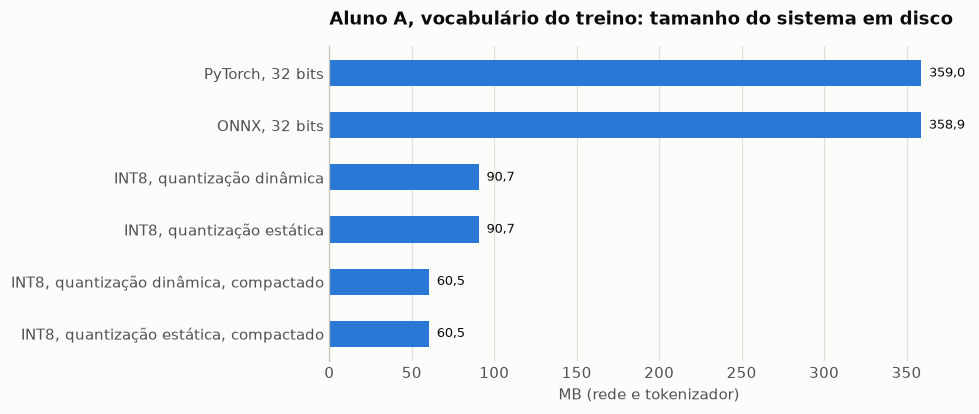

Tamanho em disco (MB), semente 0. 'Rede' é só o arquivo dos pesos; 'sistema' soma o tokenizador.


,papel,32 bits: rede,32 bits: sistema,INT8: rede,tokenizador,INT8: sistema,INT8 estática: sistema,INT8 compactado: rede,INT8 compactado: sistema,32 bits ÷ INT8 (rede),32 bits ÷ INT8 (sistema),32 bits ÷ INT8 compactado (sistema)
modelo,,,,,,,,,,,,
"Aluno A, sem poda",sem poda,"1.110,4","1.127,5","278,2","9,08","287,3","287,3","211,9","215,4","3,99×","3,92×","5,2×"
"Aluno A, vocabulário do treino",poda principal (menor arquivo),"358,3","359,0","90,2","0,48","90,7","90,7","60,3","60,5","3,97×","3,96×","5,9×"
"Aluno A, gradual 70%",poda secundária (pesos soltos),"1.110,4","1.127,5","278,2","9,08","287,3","287,3","186,3","189,9","3,99×","3,92×","5,9×"
"Teto, sem poda",sem poda,"1.110,4","1.127,5","278,2","9,08","287,3","287,3","212,0","215,5","3,99×","3,92×","5,2×"
"Teto, vocabulário do treino",poda principal (menor arquivo),"358,3","359,0","90,2","0,48","90,7","90,7","60,3","60,5","3,97×","3,96×","5,9×"
"Teto, magnitude 50%",poda secundária (pesos soltos),"1.110,4","1.127,5","278,2","9,08","287,3","287,3","198,8","202,3","3,99×","3,92×","5,6×"
"Aluno B2, sem poda",sem poda,"1.110,4","1.127,5","278,2","9,08","287,3","287,3","212,0","215,6","3,99×","3,92×","5,2×"
"Aluno B2, vocabulário do treino",poda principal (menor arquivo),"358,3","359,0","90,2","0,48","90,7","90,7","60,3","60,5","3,97×","3,96×","5,9×"
"Aluno B2, gradual 70%",poda secundária (pesos soltos),"1.110,4","1.127,5","278,2","9,08","287,3","287,3","186,3","189,8","3,99×","3,92×","5,9×"


In [8]:
def tamanhos(chave):
    f = meta0[chave]["formas"]
    t = {"pytorch": f[REFERENCIA]["bytes"], "pytorch_rede": f[REFERENCIA]["rede"], "fp32": f["fp32"]["bytes"], "fp32_rede": f["fp32"]["arquivos"][REDE],
         "tokenizador": f["fp32"]["arquivos"][TOKENIZADOR], "tokenizador_compactado": f[CANDIDATAS[0]]["arquivos_compactados"][TOKENIZADOR_COMPACTADO]}
    for forma in CANDIDATAS:
        t.update({forma: f[forma]["bytes"], f"{forma}_rede": f[forma]["arquivos"][REDE], f"{forma}_compactado": f[forma]["bytes_compactado"],
                  f"{forma}_rede_compactada": f[forma]["arquivos_compactados"][REDE_COMPACTADA]})
    return t


tam = {chave: tamanhos(chave) for chave in CHAVES}
fig, ax = visual.barras_em_ordem(
    {
        "PyTorch, 32 bits": tam[MOSTRA]["pytorch"] / 1e6, "ONNX, 32 bits": tam[MOSTRA]["fp32"] / 1e6,
        **{NOME_DA_FORMA[forma]: tam[MOSTRA][forma] / 1e6 for forma in CANDIDATAS},
        **{f"{NOME_DA_FORMA[forma]}, compactado": tam[MOSTRA][f"{forma}_compactado"] / 1e6 for forma in CANDIDATAS},
    },
    f"{CURTO[MOSTRA]}: tamanho do sistema em disco", "MB (rede e tokenizador)", formato=lambda v: num(v, 1),
)
visual.salvar(fig, PASTA, "tamanho")
plt.show()

compacta_igual = all(e["meta"]["formas"][forma]["compactado_responde_igual"] for chave in CHAVES for e in exe[chave] for forma in CANDIDATAS)
print("Tamanho em disco (MB), semente 0. 'Rede' é só o arquivo dos pesos; 'sistema' soma o tokenizador.")
pd.DataFrame([
    {
        "modelo": CURTO[chave], "papel": PAPEL[fichas[chave]["papel"]],
        "32 bits: rede": mb(tam[chave]["pytorch_rede"]), "32 bits: sistema": mb(tam[chave]["pytorch"]),
        "INT8: rede": mb(tam[chave]["dinamica_rede"]), "tokenizador": mb(tam[chave]["tokenizador"], 2), "INT8: sistema": mb(tam[chave]["dinamica"]),
        "INT8 estática: sistema": mb(tam[chave]["estatica"]),
        "INT8 compactado: rede": mb(tam[chave]["dinamica_rede_compactada"]), "INT8 compactado: sistema": mb(tam[chave]["dinamica_compactado"]),
        "32 bits ÷ INT8 (rede)": num(tam[chave]["pytorch_rede"] / tam[chave]["dinamica_rede"], 2) + "×",
        "32 bits ÷ INT8 (sistema)": num(tam[chave]["pytorch"] / tam[chave]["dinamica"], 2) + "×",
        "32 bits ÷ INT8 compactado (sistema)": num(tam[chave]["pytorch"] / tam[chave]["dinamica_compactado"], 1) + "×",
    }
    for chave in CHAVES
]).set_index("modelo")

In [9]:
t = tam[MOSTRA]
esparsidade = {chave: meta0[chave]["pesos_podaveis"]["esparsidade"] for chave in CHAVES}
linhas_de_leitura = [
    f"- **{CURTO[MOSTRA]}:** de {mb(t['pytorch'])} MB em 32 bits para {mb(t['dinamica'])} MB em INT8, {num(t['pytorch'] / t['dinamica'], 2)} vezes menos. "
    f"Só a rede vai de {mb(t['pytorch_rede'])} para {mb(t['dinamica_rede'])} MB ({num(t['pytorch_rede'] / t['dinamica_rede'], 2)} vezes). "
    f"O sistema não chega a 4 vezes porque o tokenizador ({mb(t['tokenizador'], 2)} MB) e os vieses e normalizações não encolhem.",
    f"- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de {num(abs(t['estatica'] - t['dinamica']) / 1e3, 1)} KB (as faixas das ativações, que a estática grava).",
]
if MOSTRA != SEM_PODA and SEM_PODA in tam:
    s = tam[SEM_PODA]
    linhas_de_leitura.append(
        f"- **Poda e quantização somadas** ({CURTO[MOSTRA]} contra {CURTO[SEM_PODA]} em 32 bits): de {mb(s['pytorch'])} MB para {mb(t['dinamica'])} MB, "
        f"{num(s['pytorch'] / t['dinamica'], 1)} vezes menos. A poda responde por {num(s['pytorch'] / t['pytorch'], 1)} vezes e a quantização por {num(t['pytorch'] / t['dinamica'], 2)}."
    )
for chave in com_zeros:
    s = tam[chave]
    linhas_de_leitura.append(
        f"- **{CURTO[chave]}** ({pts(esparsidade[chave])}% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem {mb(s['dinamica'])} MB, o mesmo de um modelo sem zeros, "
        f"porque um zero ocupa um byte. Compactado, vai a {mb(s['dinamica_compactado'])} MB ({num(s['pytorch'] / s['dinamica_compactado'], 1)} vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece."
    )
sem_zeros = [chave for chave in CHAVES if chave not in com_zeros]
if sem_zeros:
    ganho = np.mean([1 - tam[c]["dinamica_compactado"] / tam[c]["dinamica"] for c in sem_zeros])
    linhas_de_leitura.append(f"- Nos modelos sem pesos soltos em zero, compactar tira em média {pts(ganho)}% do sistema em INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do tokenizador.")
linhas_de_leitura.append(f"- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: {'confere em todas as execuções' if compacta_igual else '**NÃO confere**'}.")
display(Markdown("**Leitura.**\n\n" + "\n".join(linhas_de_leitura)))

**Leitura.**

- **Aluno A, vocabulário do treino:** de 359,0 MB em 32 bits para 90,7 MB em INT8, 3,96 vezes menos. Só a rede vai de 358,3 para 90,2 MB (3,97 vezes). O sistema não chega a 4 vezes porque o tokenizador (0,48 MB) e os vieses e normalizações não encolhem.
- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de 47,4 KB (as faixas das ativações, que a estática grava).
- **Poda e quantização somadas** (Aluno A, vocabulário do treino contra Aluno A, sem poda em 32 bits): de 1.127,5 MB para 90,7 MB, 12,4 vezes menos. A poda responde por 3,1 vezes e a quantização por 3,96.
- **Aluno A, gradual 70%** (70,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 189,9 MB (5,9 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Teto, magnitude 50%** (50,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 202,3 MB (5,6 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Aluno B2, gradual 70%** (70,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 189,8 MB (5,9 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- Nos modelos sem pesos soltos em zero, compactar tira em média 29,1% do sistema em INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do tokenizador.
- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: confere em todas as execuções.

## 7. Latência

Protocolo da Etapa 2 (`avaliacao/eficiencia.py`): uma consulta por vez, 1 thread, do texto à resposta, 1.024 consultas medidas depois de 50 de aquecimento, com os pedidos de `dev`. Aqui são 5 rodadas, alternando os sistemas, com o modelo da semente 0. A medida roda fora do notebook (`uv run python -m especialista.experimentos.etapa10c latencia`), com a máquina quieta.

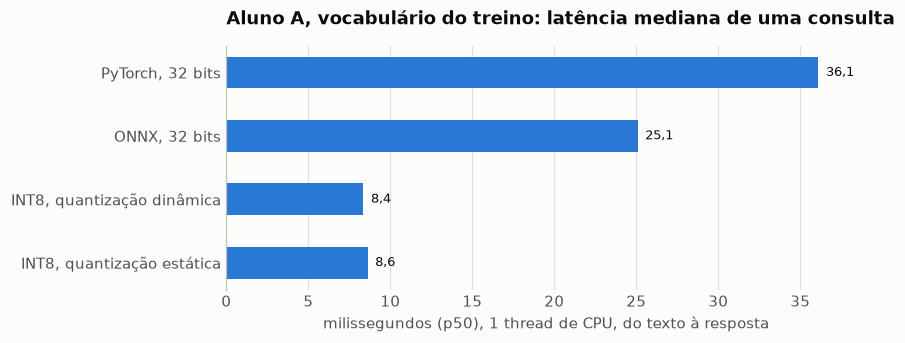

Latência em milissegundos, semente 0: p50 (do menor ao maior p50 entre as 5 rodadas) e p95


,"PyTorch, 32 bits","ONNX, 32 bits","INT8, quantização dinâmica","INT8, quantização estática"
modelo,,,,
"Aluno A, sem poda","35,82 (35,35 a 37,04); p95 47,97","25,03 (24,72 a 25,26); p95 36,85","8,33 (8,25 a 8,41); p95 11,94","8,65 (8,58 a 8,70); p95 12,43"
"Aluno A, vocabulário do treino","36,10 (35,95 a 36,36); p95 49,04","25,08 (24,79 a 25,32); p95 37,30","8,35 (8,20 a 8,50); p95 12,22","8,61 (8,56 a 8,70); p95 12,68"
"Aluno A, gradual 70%","36,14 (35,62 a 36,62); p95 47,88","25,14 (24,99 a 25,48); p95 37,05","8,37 (8,31 a 8,48); p95 12,05","8,74 (8,64 a 8,82); p95 12,49"
"Teto, sem poda","37,06 (36,56 a 37,41); p95 48,67","25,19 (25,07 a 25,41); p95 37,15","8,39 (8,30 a 8,59); p95 12,21","8,85 (8,80 a 8,91); p95 12,70"
"Teto, vocabulário do treino","37,54 (37,33 a 37,80); p95 50,54","25,35 (25,21 a 25,64); p95 37,51","8,50 (8,37 a 8,69); p95 12,43","8,75 (8,59 a 8,94); p95 12,79"
"Teto, magnitude 50%","37,01 (36,61 a 37,51); p95 48,80","25,45 (24,95 a 25,83); p95 37,31","8,37 (8,22 a 8,48); p95 11,98","8,78 (8,62 a 8,94); p95 12,63"
"Aluno B2, sem poda","37,58 (37,08 a 38,18); p95 49,29","25,23 (24,40 a 25,59); p95 36,92","8,26 (7,95 a 8,46); p95 11,95","8,67 (8,33 a 8,78); p95 12,48"
"Aluno B2, vocabulário do treino","36,80 (36,53 a 37,07); p95 49,23","24,33 (24,08 a 24,43); p95 36,33","7,94 (7,83 a 8,02); p95 11,85","8,24 (8,08 a 8,38); p95 12,20"
"Aluno B2, gradual 70%","36,87 (36,64 a 37,47); p95 48,38","24,23 (24,05 a 24,42); p95 35,99","8,01 (7,91 a 8,08); p95 11,54","8,30 (8,22 a 8,44); p95 12,07"


In [10]:
p50 = {chave: {forma: lat[chave]["resumo"][forma]["latencia_p50_ms"] for forma in etapa10c.COM_LATENCIA} for chave in CHAVES}
p95 = {chave: {forma: lat[chave]["resumo"][forma]["latencia_p95_ms"] for forma in etapa10c.COM_LATENCIA} for chave in CHAVES}
rodadas = {chave: lat[chave]["p50_por_rodada_ms"] for chave in CHAVES}

# A máquina estava quieta? Duas conferências: quanto de CPU os outros processos usaram durante cada medida (o pior caso),
# e o modelo sem poda em PyTorch contra a latência que a Etapa 10a mediu.
outros_processos = max(l["nucleos_de_outros"] for l in lat.values())   # em núcleos de CPU
LIMITE_DE_OUTROS = 0.25
na_10a = float(da_10a["custo_de_partida"]["latencia_p50_ms_cpu_1_thread"])
agora = p50[SEM_PODA][REFERENCIA] if SEM_PODA in p50 else None
maquina_quieta = bool(outros_processos <= LIMITE_DE_OUTROS and (agora is None or agora <= 1.2 * na_10a))

fig, ax = visual.barras_em_ordem(
    {NOME_DA_FORMA[forma]: p50[MOSTRA][forma] for forma in etapa10c.COM_LATENCIA},
    f"{CURTO[MOSTRA]}: latência mediana de uma consulta", "milissegundos (p50), 1 thread de CPU, do texto à resposta", formato=lambda v: num(v, 1),
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

print("Latência em milissegundos, semente 0: p50 (do menor ao maior p50 entre as 5 rodadas) e p95")
celula = lambda chave, forma: f"{num(p50[chave][forma], 2)} ({num(min(rodadas[chave][forma]), 2)} a {num(max(rodadas[chave][forma]), 2)}); p95 {num(p95[chave][forma], 2)}"
pd.DataFrame([{"modelo": CURTO[chave], **{NOME_DA_FORMA[forma]: celula(chave, forma) for forma in etapa10c.COM_LATENCIA}} for chave in CHAVES]).set_index("modelo")

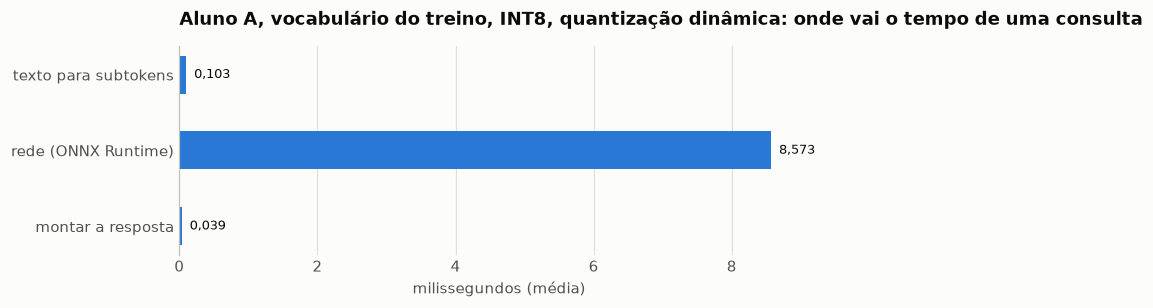

Aluno A, vocabulário do treino: tempo médio de cada trecho de uma consulta (ms)


,"ONNX, 32 bits","INT8, quantização dinâmica","INT8, quantização estática"
texto para subtokens,"0,121","0,103","0,103"
rede (ONNX Runtime),"26,651","8,573","8,847"
montar a resposta,"0,047","0,039","0,039"



**Leitura.**

- **A máquina estava quieta?** Sim. Durante as medidas, os outros processos da máquina ocuparam no máximo 0,08 núcleo de CPU, dos 24 que ela tem (o limite da etapa é 0,25). O Aluno A, sem poda, em PyTorch, deu 35,8 ms; na Etapa 10a, 36,1 ms.
- **Sair do PyTorch:** na média dos modelos, o ONNX de 32 bits é 1,47 vezes mais rápido que o mesmo modelo em PyTorch. Na rede do zero (Etapa 8) esse fator era de 2,6: lá as contas eram pequenas e o que pesava era o custo fixo de cada operação do PyTorch. Aqui as multiplicações são grandes, e os dois executores gastam a maior parte do tempo nelas.
- **Passar para 8 bits**, na média dos modelos, deixa a consulta 3,02 vezes mais rápida com INT8, quantização dinâmica, 2,90 vezes mais rápida com INT8, quantização estática, em relação ao ONNX de 32 bits (menos de 1 = mais lenta). Do PyTorch de 32 bits ao INT8: 4,44 vezes com INT8, quantização dinâmica, 4,27 vezes com INT8, quantização estática.
- **Estática contra dinâmica:** a estática é mais rápida em todas as rodadas em 0 de 9 modelos; a dinâmica, em 9.
- **Onde vai o tempo** (Aluno A, vocabulário do treino, INT8, quantização dinâmica): a rede leva 98% da consulta; o tokenizador, 1%.


In [11]:
trechos = pd.DataFrame({NOME_DA_FORMA[forma]: lat[MOSTRA]["tempo_por_trecho_ms"][forma] for forma in ("fp32", *CANDIDATAS)})
fig, ax = visual.barras_em_ordem(
    dict(trechos[NOME_DA_FORMA["dinamica"]]), f"{CURTO[MOSTRA]}, {NOME_DA_FORMA['dinamica']}: onde vai o tempo de uma consulta", "milissegundos (média)",
    formato=lambda v: num(v, 3),
)
visual.salvar(fig, PASTA, "tempo_por_trecho")
plt.show()
print(f"{CURTO[MOSTRA]}: tempo médio de cada trecho de uma consulta (ms)")
display(trechos.map(lambda v: num(v, 3)))

ganho_onnx = np.mean([p50[c][REFERENCIA] / p50[c]["fp32"] for c in CHAVES])
ganho_int8 = {forma: np.mean([p50[c]["fp32"] / p50[c][forma] for c in CHAVES]) for forma in CANDIDATAS}
ganho_total = {forma: np.mean([p50[c][REFERENCIA] / p50[c][forma] for c in CHAVES]) for forma in CANDIDATAS}
estatica_mais_rapida = [c for c in CHAVES if all(e < d for e, d in zip(rodadas[c]["estatica"], rodadas[c]["dinamica"]))]
dinamica_mais_rapida = [c for c in CHAVES if all(d < e for e, d in zip(rodadas[c]["estatica"], rodadas[c]["dinamica"]))]
d = trechos[NOME_DA_FORMA["dinamica"]]
onnx_na_8 = da_8["latencia_p50_ms"]["pytorch"] / da_8["latencia_p50_ms"]["fp32"]          # na rede do zero: o que sair do PyTorch rendeu
int8_na_8 = da_8["latencia_p50_ms"]["fp32"] / da_8["latencia_p50_ms"][da_8["forma"]]       # e o que os 8 bits renderam
display(Markdown(f"""
**Leitura.**

- **A máquina estava quieta?** {"Sim" if maquina_quieta else "**Não**"}. Durante as medidas, os outros processos da máquina ocuparam no máximo {num(outros_processos, 2)} núcleo de CPU, dos {etapa10c.ambiente()["cpus_logicas"]} que ela tem (o limite da etapa é {num(LIMITE_DE_OUTROS, 2)}).{f" O {CURTO[SEM_PODA]}, em PyTorch, deu {num(agora, 1)} ms; na Etapa 10a, {num(na_10a, 1)} ms." if agora is not None else ""}{"" if maquina_quieta else " **As latências abaixo estão infladas e não valem como resultado.**"}
- **Sair do PyTorch:** na média dos modelos, o ONNX de 32 bits é {num(ganho_onnx, 2)} vezes mais rápido que o mesmo modelo em PyTorch. Na rede do zero (Etapa 8) esse fator era de {num(onnx_na_8, 1)}: lá as contas eram pequenas e o que pesava era o custo fixo de cada operação do PyTorch. Aqui as multiplicações são grandes, e os dois executores gastam a maior parte do tempo nelas.
- **Passar para 8 bits**, na média dos modelos, deixa a consulta {", ".join(f"{num(v, 2)} vezes mais rápida com {NOME_DA_FORMA[f]}" for f, v in ganho_int8.items())}, em relação ao ONNX de 32 bits (menos de 1 = mais lenta). Do PyTorch de 32 bits ao INT8: {", ".join(f"{num(v, 2)} vezes com {NOME_DA_FORMA[f]}" for f, v in ganho_total.items())}.
- **Estática contra dinâmica:** a estática é mais rápida em todas as rodadas em {len(estatica_mais_rapida)} de {len(CHAVES)} modelos; a dinâmica, em {len(dinamica_mais_rapida)}.
- **Onde vai o tempo** ({CURTO[MOSTRA]}, {NOME_DA_FORMA["dinamica"]}): a rede leva {pts(d["rede (ONNX Runtime)"] / d.sum(), 0)}% da consulta; o tokenizador, {pts(d["texto para subtokens"] / d.sum(), 0)}%.
"""))

## 8. A forma final de cada modelo

A regra da seção 2 (itens 11 e 12), aplicada a cada modelo em `dev`. Depois, o teste, para a forma escolhida.

A regra em dev: F1 de entidades de cada forma menos o do mesmo modelo em 32 bits (intervalo de 95%)


,"INT8, quantização dinâmica: queda","INT8, quantização estática: queda","INT8, quantização dinâmica: passa","INT8, quantização estática: passa",fica,por quê
modelo,,,,,,
"Aluno A, sem poda","+0,22 (−0,28 a +0,71)","−9,26 (−10,64 a −7,80)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Aluno A, vocabulário do treino","+0,05 (−0,39 a +0,50)","−9,78 (−11,08 a −8,36)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Aluno A, gradual 70%","−0,47 (−0,93 a −0,02)","−4,43 (−5,67 a −3,15)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Teto, sem poda","−0,10 (−0,67 a +0,49)","−14,94 (−16,32 a −13,60)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Teto, vocabulário do treino","−0,20 (−0,72 a +0,34)","−13,63 (−14,98 a −12,34)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Teto, magnitude 50%","−0,52 (−1,10 a +0,05)","−13,69 (−14,99 a −12,39)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Aluno B2, sem poda","+0,20 (−0,38 a +0,76)","−10,83 (−12,26 a −9,41)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Aluno B2, vocabulário do treino","−0,16 (−0,66 a +0,37)","−11,72 (−13,06 a −10,32)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades
"Aluno B2, gradual 70%","−0,46 (−0,99 a +0,04)","−1,74 (−2,82 a −0,56)",sim,NÃO,"INT8, quantização dinâmica",é a única que fica dentro de 1 ponto de F1 de entidades


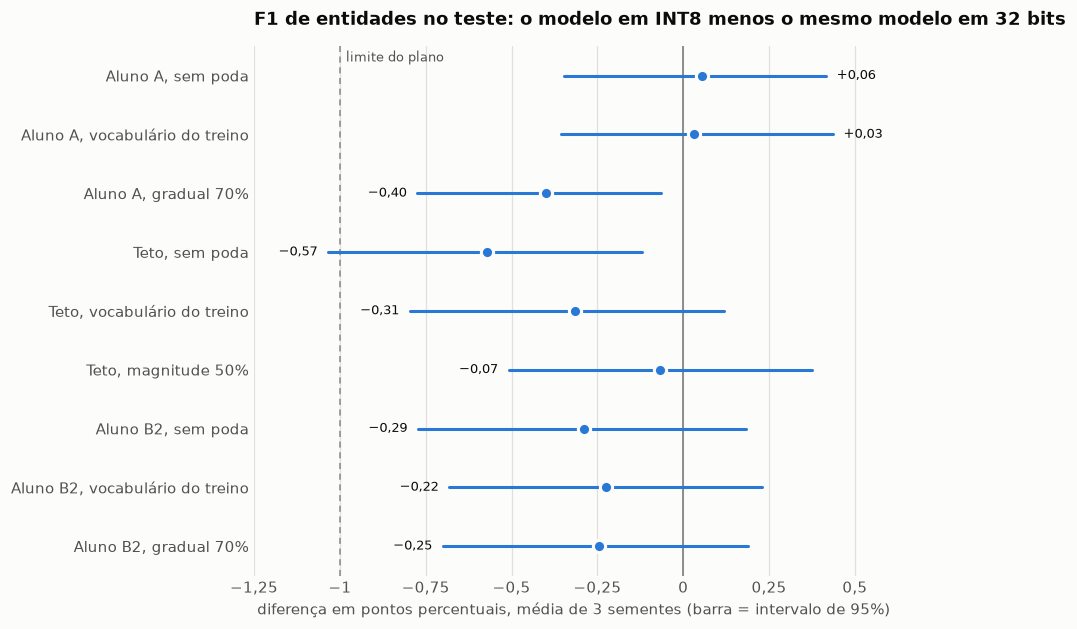

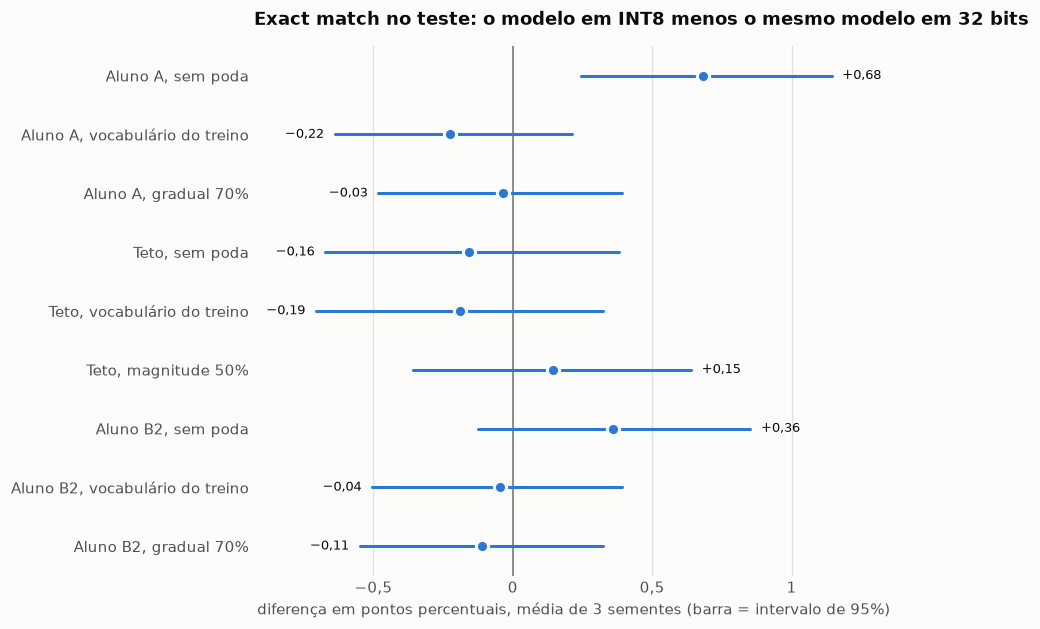

Teste, em % (intervalo de 95%), média de 3 sementes: o modelo em 32 bits, o mesmo em INT8 e a diferença pareada


32 bits  \
modelo                          forma                      métrica                                    
Aluno A, sem poda               INT8, quantização dinâmica Acurácia de intenção  82,6 (81,4 a 84,0)   
                                                           Macro-F1 de intenção  79,9 (78,0 a 82,5)   
                                                           F1 de entidades       65,5 (64,0 a 67,2)   
                                                           Exact match           53,8 (52,1 a 55,4)   
Aluno A, vocabulário do treino  INT8, quantização dinâmica Acurácia de intenção  82,9 (81,6 a 84,2)   
                                                           Macro-F1 de intenção  80,6 (78,8 a 83,0)   
                                                           F1 de entidades       65,1 (63,5 a 66,8)   
                                                           Exact match           53,7 (52,0 a 55,3)   
Aluno A, gradual 70%            INT8, quantização dinâmica Acurácia de intenção  82,2 (80,9 a 83,5)   
                                                           Macro-F1 de intenção  79,4 (77,4 a 81,9)   
                                                           F1 de entidades       64,6 (63,0 a 66,2)   
                                                           Exact match           53,0 (51,2 a 54,7)   
Teto, sem poda                  INT8, quantização dinâmica Acurácia de intenção  86,9 (85,8 a 88,0)   
                                                           Macro-F1 de intenção  83,1 (81,2 a 85,8)   
                                                           F1 de entidades       75,5 (74,0 a 77,0)   
                                                           Exact match           66,3 (64,7 a 67,9)   
Teto, vocabulário do treino     INT8, quantização dinâmica Acurácia de intenção  86,7 (85,5 a 87,7)   
                                                           Macro-F1 de intenção  83,6 (81,7 a 86,2)   
                                                           F1 de entidades       74,9 (73,4 a 76,4)   
                                                           Exact match           65,8 (64,2 a 67,4)   
Teto, magnitude 50%             INT8, quantização dinâmica Acurácia de intenção  86,7 (85,5 a 87,8)   
                                                           Macro-F1 de intenção  83,4 (81,4 a 85,9)   
                                                           F1 de entidades       74,5 (73,0 a 76,0)   
                                                           Exact match           65,4 (63,9 a 67,0)   
Aluno B2, sem poda              INT8, quantização dinâmica Acurácia de intenção  78,9 (77,5 a 80,3)   
                                                           Macro-F1 de intenção  76,9 (74,9 a 79,4)   
                                                           F1 de entidades       58,8 (57,1 a 60,5)   
                                                           Exact match           46,3 (44,6 a 48,0)   
Aluno B2, vocabulário do treino INT8, quantização dinâmica Acurácia de intenção  78,4 (77,0 a 79,8)   
                                                           Macro-F1 de intenção  76,2 (74,3 a 78,7)   
                                                           F1 de entidades       57,9 (56,2 a 59,6)   
                                                           Exact match           45,2 (43,5 a 47,0)   
Aluno B2, gradual 70%           INT8, quantização dinâmica Acurácia de intenção  78,1 (76,7 a 79,6)   
                                                           Macro-F1 de intenção  76,0 (74,1 a 78,5)   
                                                           F1 de entidades       58,7 (57,0 a 60,3)   
                                                           Exact match           45,8 (44,0 a 47,5)   

                                                                                               INT8  \
modelo                          forma                      métrica        

In [12]:
decisoes = {
    chave: etapa10c.escolher_forma(ouro_dev, {forma: grupo(chave, forma, "dev") for forma in (REFERENCIA, *CANDIDATAS)}, rodadas[chave])
    for chave in CHAVES
}
ESCOLHIDA = {chave: decisoes[chave]["forma"] for chave in CHAVES}
precisam_de_qat = [chave for chave in CHAVES if decisoes[chave]["precisa_de_qat"]]

print("A regra em dev: F1 de entidades de cada forma menos o do mesmo modelo em 32 bits (intervalo de 95%)")
display(pd.DataFrame([
    {
        "modelo": CURTO[chave],
        **{f"{NOME_DA_FORMA[forma]}: queda": com_intervalo(decisoes[chave]["tabela"].loc[forma], 2) for forma in CANDIDATAS},
        **{f"{NOME_DA_FORMA[forma]}: passa": "sim" if decisoes[chave]["tabela"].loc[forma, "passa"] else "NÃO" for forma in CANDIDATAS},
        "fica": NOME_DA_FORMA[ESCOLHIDA[chave]] if ESCOLHIDA[chave] else "nenhuma: QAT", "por quê": decisoes[chave]["motivo"],
    }
    for chave in CHAVES
]).set_index("modelo"))

# O teste, para a forma escolhida de cada modelo (e para o ONNX de 32 bits, que tem de dar zero)
com_forma = [chave for chave in CHAVES if ESCOLHIDA[chave]]
contra["test"] = {
    chave: {forma: qualidade.comparar_grupos(ouro_teste, grupo(chave, REFERENCIA, "test"), grupo(chave, forma, "test")) for forma in ("fp32", ESCOLHIDA[chave])}
    for chave in com_forma
}
medidas = {
    particao: {chave: {forma: qualidade.intervalo_do_grupo(gabarito[particao], grupo(chave, forma, particao)) for forma in (REFERENCIA, ESCOLHIDA[chave])} for chave in com_forma}
    for particao in ("dev", "test")
}
if com_forma:
    fig, ax = diferencas(
        {CURTO[chave]: trio(contra["test"][chave][ESCOLHIDA[chave]].loc["slot_f1"]) for chave in com_forma},
        "F1 de entidades no teste: o modelo em INT8 menos o mesmo modelo em 32 bits", "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)",
        limite=-100 * LIMITE,
    )
    visual.salvar(fig, PASTA, "queda_no_teste")
    plt.show()
    fig, ax = diferencas(
        {CURTO[chave]: trio(contra["test"][chave][ESCOLHIDA[chave]].loc["exact_match"]) for chave in com_forma},
        "Exact match no teste: o modelo em INT8 menos o mesmo modelo em 32 bits", "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)",
    )
    visual.salvar(fig, PASTA, "queda_no_teste_exact_match")
    plt.show()

print("Teste, em % (intervalo de 95%), média de 3 sementes: o modelo em 32 bits, o mesmo em INT8 e a diferença pareada")
linhas_do_teste = [
    {
        "modelo": CURTO[chave], "forma": NOME_DA_FORMA[ESCOLHIDA[chave]], "métrica": qualidade.NOMES[m],
        "32 bits": valor_com_intervalo(medidas["test"][chave][REFERENCIA].loc[m]), "INT8": valor_com_intervalo(medidas["test"][chave][ESCOLHIDA[chave]].loc[m]),
        "INT8 − 32 bits": com_intervalo(contra["test"][chave][ESCOLHIDA[chave]].loc[m], 2),
    }
    for chave in com_forma for m in qualidade.METRICAS
]
pd.DataFrame(linhas_do_teste).set_index(["modelo", "forma", "métrica"]) if linhas_do_teste else None

In [13]:
def frase_do_modelo(chave):
    if decisoes[chave]["precisa_de_qat"]:
        return f"**{CURTO[chave]}:** nenhuma forma pós-treino passa. Pela regra do plano, este modelo precisa de treino ciente de quantização."
    forma, t = ESCOLHIDA[chave], contra["test"][chave][ESCOLHIDA[chave]]
    return (f"**{CURTO[chave]}:** fica a {NOME_DA_FORMA[forma]} ({decisoes[chave]['motivo']}). No teste, em relação ao mesmo modelo em 32 bits: "
            f"{com_intervalo(t.loc['intent_acc'], 2)} em intenção, {com_intervalo(t.loc['slot_f1'], 2)} em entidades e {com_intervalo(t.loc['exact_match'], 2)} em exact match.")


nao_passam = [(chave, forma) for chave in CHAVES for forma in CANDIDATAS if not decisoes[chave]["tabela"].loc[forma, "passa"]]
distinguiveis_no_teste = [(chave, m) for chave in com_forma for m in TRES if contra["test"][chave][ESCOLHIDA[chave]].loc[m, "distinguivel"]]
if precisam_de_qat:
    frase_do_qat = ("**Treino ciente de quantização:** a regra do plano manda fazer para " + ", ".join(CURTO[c] for c in precisam_de_qat)
                    + ". Esta etapa não fecha sem ele.")
else:
    frase_do_qat = (f"**Treino ciente de quantização:** não entra. Em todo modelo há uma forma pós-treino cujo F1 de entidades cai no máximo {num(100 * LIMITE, 0)} ponto em `dev`, "
                    "que era a condição do plano.")
def resumo_das_que_nao_passam():
    # Uma frase por forma: em quantos modelos ela não passa e em que faixa fica a diferença (o número de cada modelo está na tabela da regra)
    partes = []
    for f in CANDIDATAS:
        modelos_f = [c for c, forma in nao_passam if forma == f]
        if not modelos_f:
            continue
        quedas_f = [decisoes[c]["tabela"].loc[f, "diferenca"] for c in modelos_f]
        onde = f"em nenhum dos {len(CHAVES)} modelos" if len(modelos_f) == len(CHAVES) else f"em {len(modelos_f)} dos {len(CHAVES)} modelos ({'; '.join(CURTO[c] for c in modelos_f)})"
        faixa = (f"vai de {dif(max(quedas_f), 2)} a {dif(min(quedas_f), 2)} pontos conforme o modelo" if len(modelos_f) > 1 else f"é de {dif(quedas_f[0], 2)} ponto")
        partes.append(f"a {NOME_DA_FORMA[f]} não passa {onde}; a diferença de F1 de entidades em `dev`, para o mesmo modelo em 32 bits, {faixa}")
    return "**Formas que não passam na regra:** " + ("nenhuma." if not partes else ". ".join(parte[0].upper() + parte[1:] for parte in partes) + ".")


frase_das_que_nao_passam = resumo_das_que_nao_passam()
if FINAL is None:
    frase_do_final = "**A Etapa 10b ainda não marcou o modelo principal deste caminho**; sem a decisão dela, esta etapa não tem modelo final."
elif ESCOLHIDA[FINAL] is None:
    frase_do_final = f"**O modelo final deste caminho** seria o {CURTO[FINAL]}, mas ele não passou na regra: depende do treino ciente de quantização."
else:
    frase_do_final = (f"**O modelo final do caminho do encoder pré-treinado** é o **{fichas[FINAL]['nome']}, em {NOME_DA_FORMA[ESCOLHIDA[FINAL]]}**: "
                      f"{mb(tam[FINAL][ESCOLHIDA[FINAL]])} MB em disco e {num(p50[FINAL][ESCOLHIDA[FINAL]], 2)} ms por consulta (p50), "
                      f"contra {mb(tam[FINAL]['pytorch'])} MB e {num(p50[FINAL][REFERENCIA], 2)} ms do mesmo modelo em 32 bits no PyTorch"
                      + (f", e {mb(tam[SEM_PODA]['pytorch'])} MB e {num(p50[SEM_PODA][REFERENCIA], 2)} ms do modelo sem poda." if FINAL != SEM_PODA else "."))
# A variante de pesos soltos do modelo principal: menor no disco depois do zip, mas não na memória
SECUNDARIA = next((c for c in CHAVES if FINAL and c[0] == FINAL[0] and fichas[c]["papel"] == "secundaria" and ESCOLHIDA[c]), None)
frase_da_secundaria = ""
if SECUNDARIA and ESCOLHIDA[FINAL]:
    f_final, f_sec = ESCOLHIDA[FINAL], ESCOLHIDA[SECUNDARIA]
    entre_variantes = qualidade.comparar_grupos(ouro_teste, grupo(FINAL, f_final, "test"), grupo(SECUNDARIA, f_sec, "test")).loc["exact_match"]   # pesos soltos − final
    onde = {"acima": "acima do", "abaixo": "abaixo do", "sem diferença distinguível": "sem diferença distinguível para o"}[posicao(entre_variantes)]
    frase_da_secundaria = (
        f"**A variante de pesos soltos do mesmo modelo** ({CURTO[SECUNDARIA]}) fica com {mb(tam[SECUNDARIA][f_sec + '_compactado'])} MB em INT8 compactado, "
        f"{'menos' if tam[SECUNDARIA][f_sec + '_compactado'] < tam[FINAL][f_final + '_compactado'] else 'mais'} que o modelo final "
        f"({mb(tam[FINAL][f_final])} MB, ou {mb(tam[FINAL][f_final + '_compactado'])} MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, "
        f"ela ocupa {mb(tam[SECUNDARIA][f_sec])} MB, e a latência é {num(p50[SECUNDARIA][f_sec], 2)} ms. "
        f"No teste, em exact match, ela fica {onde} modelo final ({com_intervalo(entre_variantes, 2)}). "
        "O modelo final continua sendo a variante que a Etapa 10b marcou como principal: a regra foi escrita antes da medida."
    )
display(Markdown("**Decisão.**\n\n" + "\n".join(f"- {frase_do_modelo(chave)}" for chave in CHAVES) + f"""
- {frase_das_que_nao_passam}
- **Diferenças distinguíveis de zero no teste**, na forma escolhida: {"nenhuma" if not distinguiveis_no_teste else "; ".join(f"{CURTO[c]}, {qualidade.NOMES[m]}: {com_intervalo(contra['test'][c][ESCOLHIDA[c]].loc[m], 2)}" for c, m in distinguiveis_no_teste)}.{acaso(len(distinguiveis_no_teste), len(com_forma) * len(TRES))}
- {frase_do_qat}
- {frase_do_final}
""" + (f"- {frase_da_secundaria}\n" if frase_da_secundaria else "")))

**Decisão.**

- **Aluno A, sem poda:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: +0,15 (−0,20 a +0,49) em intenção, +0,06 (−0,35 a +0,42) em entidades e +0,68 (+0,25 a +1,14) em exact match.
- **Aluno A, vocabulário do treino:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,44 (−0,77 a −0,10) em intenção, +0,03 (−0,36 a +0,44) em entidades e −0,22 (−0,64 a +0,21) em exact match.
- **Aluno A, gradual 70%:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,17 (−0,49 a +0,17) em intenção, −0,40 (−0,77 a −0,06) em entidades e −0,03 (−0,48 a +0,39) em exact match.
- **Teto, sem poda:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,17 (−0,50 a +0,18) em intenção, −0,57 (−1,03 a −0,12) em entidades e −0,16 (−0,67 a +0,38) em exact match.
- **Teto, vocabulário do treino:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,36 (−0,72 a −0,01) em intenção, −0,31 (−0,80 a +0,12) em entidades e −0,19 (−0,71 a +0,33) em exact match.
- **Teto, magnitude 50%:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,03 (−0,38 a +0,34) em intenção, −0,07 (−0,51 a +0,37) em entidades e +0,15 (−0,36 a +0,64) em exact match.
- **Aluno B2, sem poda:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: +0,09 (−0,25 a +0,46) em intenção, −0,29 (−0,77 a +0,18) em entidades e +0,36 (−0,12 a +0,85) em exact match.
- **Aluno B2, vocabulário do treino:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,18 (−0,54 a +0,16) em intenção, −0,22 (−0,68 a +0,23) em entidades e −0,04 (−0,50 a +0,39) em exact match.
- **Aluno B2, gradual 70%:** fica a INT8, quantização dinâmica (é a única que fica dentro de 1 ponto de F1 de entidades). No teste, em relação ao mesmo modelo em 32 bits: −0,04 (−0,40 a +0,31) em intenção, −0,25 (−0,70 a +0,19) em entidades e −0,11 (−0,55 a +0,33) em exact match.
- **Formas que não passam na regra:** A INT8, quantização estática não passa em nenhum dos 9 modelos; a diferença de F1 de entidades em `dev`, para o mesmo modelo em 32 bits, vai de −1,74 a −14,94 pontos conforme o modelo.
- **Diferenças distinguíveis de zero no teste**, na forma escolhida: Aluno A, sem poda, Exact match: +0,68 (+0,25 a +1,14); Aluno A, vocabulário do treino, Acurácia de intenção: −0,44 (−0,77 a −0,10); Aluno A, gradual 70%, F1 de entidades: −0,40 (−0,77 a −0,06); Teto, sem poda, F1 de entidades: −0,57 (−1,03 a −0,12); Teto, vocabulário do treino, Acurácia de intenção: −0,36 (−0,72 a −0,01). São 5 em 27 comparações; com intervalos de 95%, cerca de 1,4 sairia do zero só por acaso.
- **Treino ciente de quantização:** não entra. Em todo modelo há uma forma pós-treino cujo F1 de entidades cai no máximo 1 ponto em `dev`, que era a condição do plano.
- **O modelo final do caminho do encoder pré-treinado** é o **Aluno A (rótulos do Claude Haiku 5.5), vocabulário do treino, em INT8, quantização dinâmica**: 90,7 MB em disco e 8,35 ms por consulta (p50), contra 359,0 MB e 36,10 ms do mesmo modelo em 32 bits no PyTorch, e 1.127,5 MB e 35,82 ms do modelo sem poda.
- **A variante de pesos soltos do mesmo modelo** (Aluno A, gradual 70%) fica com 189,9 MB em INT8 compactado, mais que o modelo final (90,7 MB, ou 60,5 MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, ela ocupa 287,3 MB, e a latência é 8,37 ms. No teste, em exact match, ela fica sem diferença distinguível para o modelo final (−0,56 (−1,41 a +0,34)). O modelo final continua sendo a variante que a Etapa 10b marcou como principal: a regra foi escrita antes da medida.


### O que a regra não olha: a intenção. E dev contra teste

A regra decide pelo F1 de entidades. A acurácia de intenção e o exact match são medidos do mesmo jeito e reportados ao lado, em `dev` e no teste. Para o registro, o teste também é calculado para a forma que não ficou; esse número não entra em nenhuma decisão.

In [14]:
def no_teste_de(chave, forma):
    pronta = contra["test"].get(chave, {}).get(forma)
    return pronta if pronta is not None else qualidade.comparar_grupos(ouro_teste, grupo(chave, REFERENCIA, "test"), grupo(chave, forma, "test"))


registro = {"dev": contra["dev"], "test": {chave: {forma: no_teste_de(chave, forma) for forma in ("fp32", *CANDIDATAS)} for chave in CHAVES}}

# A intenção, com a forma escolhida
intencao = {chave: {p: registro[p][chave][ESCOLHIDA[chave]].loc["intent_acc"] for p in ("dev", "test")} for chave in com_forma}
cai = {p: [chave for chave in com_forma if intencao[chave][p]["ic_max"] < 0] for p in ("dev", "test")}
cai_nas_duas = [chave for chave in cai["dev"] if chave in cai["test"]]
media_da_intencao = {p: np.mean([intencao[chave][p]["diferenca"] for chave in com_forma]) for p in ("dev", "test")}
faixa_da_intencao = {p: (min(intencao[c][p]["diferenca"] for c in com_forma), max(intencao[c][p]["diferenca"] for c in com_forma)) for p in ("dev", "test")}
onde_cai = lambda chave: " e ".join(nome for p, nome in (("dev", "dev"), ("test", "teste")) if chave in cai[p]) or "não"
print("Acurácia de intenção: a forma escolhida menos o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes")
display(pd.DataFrame([
    {"modelo": CURTO[chave], "forma": NOME_DA_FORMA[ESCOLHIDA[chave]], "dev": com_intervalo(intencao[chave]["dev"], 2), "teste": com_intervalo(intencao[chave]["test"], 2),
     "queda distinguível de zero": onde_cai(chave)}
    for chave in com_forma
]).set_index("modelo"))

# Dev contra teste, na forma escolhida: onde as duas partições não dizem o mesmo sobre a diferença para o modelo em 32 bits
discordancias = [(chave, m) for chave in com_forma for m in TRES
                 if posicao(registro["dev"][chave][ESCOLHIDA[chave]].loc[m]) != posicao(registro["test"][chave][ESCOLHIDA[chave]].loc[m])]
maior_discordancia = max((abs(registro[p][c][ESCOLHIDA[c]].loc[m, "diferenca"]) for c, m in discordancias for p in ("dev", "test")), default=0.0)
nao_escolhidas = [(chave, forma) for chave in CHAVES for forma in CANDIDATAS if forma != ESCOLHIDA[chave]]
queda_das_nao_escolhidas = {p: [registro[p][c][f].loc["slot_f1", "diferenca"] for c, f in nao_escolhidas] for p in ("dev", "test")}

nomes = lambda chaves: "; ".join(CURTO[c] for c in chaves) if chaves else "nenhum"
frase_da_intencao = (
    f"**A intenção, que a regra não olha.** A regra decide pelo F1 de entidades. Com a forma escolhida, a acurácia de intenção muda, em relação ao mesmo modelo em 32 bits, "
    f"de {dif(faixa_da_intencao['dev'][0], 2)} a {dif(faixa_da_intencao['dev'][1], 2)} ponto em `dev` (média dos {len(com_forma)} modelos: {dif(media_da_intencao['dev'], 2)}) "
    f"e de {dif(faixa_da_intencao['test'][0], 2)} a {dif(faixa_da_intencao['test'][1], 2)} no teste (média: {dif(media_da_intencao['test'], 2)}). "
    f"A queda é distinguível de zero em {len(cai['dev'])} dos {len(com_forma)} modelos em `dev` ({nomes(cai['dev'])}) e em {len(cai['test'])} no teste ({nomes(cai['test'])}); "
    f"nas duas partições ao mesmo tempo, em {len(cai_nas_duas)} ({nomes(cai_nas_duas)})."
    + ("" if FINAL is None or FINAL not in intencao else
       f" No modelo final ({CURTO[FINAL]}): {com_intervalo(intencao[FINAL]['dev'], 2)} em `dev` e {com_intervalo(intencao[FINAL]['test'], 2)} no teste"
       + (", distinguível nas duas." if FINAL in cai_nas_duas else "."))
)
frase_do_dev_e_teste = (
    f"**Dev e teste.** Na forma escolhida, `dev` e teste não dizem o mesmo sobre a diferença para o modelo em 32 bits em {len(discordancias)} de {len(com_forma) * len(TRES)} comparações (modelo × métrica)"
    + ("." if not discordancias else ": " + "; ".join(
        f"{CURTO[c]}, {qualidade.NOMES[m]}: {com_intervalo(registro['dev'][c][ESCOLHIDA[c]].loc[m], 2)} em `dev` e {com_intervalo(registro['test'][c][ESCOLHIDA[c]].loc[m], 2)} no teste" for c, m in discordancias)
       + f". A maior dessas diferenças, em valor absoluto, é de {num(100 * maior_discordancia, 2)} ponto. A decisão sai de `dev`, pelo F1 de entidades, e não depende delas.")
)
frase_da_que_nao_ficou = "" if not nao_escolhidas else (
    f"**A forma que não ficou**, para o registro: no teste, o F1 de entidades dela muda de {dif(min(queda_das_nao_escolhidas['test']), 2)} a {dif(max(queda_das_nao_escolhidas['test']), 2)} pontos conforme o modelo "
    f"(em `dev`, de {dif(min(queda_das_nao_escolhidas['dev']), 2)} a {dif(max(queda_das_nao_escolhidas['dev']), 2)}). Ela fica guardada na entrega, marcada como não escolhida."
)
display(Markdown(f"**Leitura.**\n\n- {frase_da_intencao}\n- {frase_do_dev_e_teste}\n" + (f"- {frase_da_que_nao_ficou}\n" if frase_da_que_nao_ficou else "")))

Acurácia de intenção: a forma escolhida menos o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes


,forma,dev,teste,queda distinguível de zero
modelo,,,,
"Aluno A, sem poda","INT8, quantização dinâmica","−0,28 (−0,66 a +0,08)","+0,15 (−0,20 a +0,49)",não
"Aluno A, vocabulário do treino","INT8, quantização dinâmica","−0,41 (−0,79 a −0,03)","−0,44 (−0,77 a −0,10)",dev e teste
"Aluno A, gradual 70%","INT8, quantização dinâmica","−0,07 (−0,49 a +0,33)","−0,17 (−0,49 a +0,17)",não
"Teto, sem poda","INT8, quantização dinâmica","−0,49 (−0,98 a −0,05)","−0,17 (−0,50 a +0,18)",dev
"Teto, vocabulário do treino","INT8, quantização dinâmica","−0,46 (−0,95 a +0,00)","−0,36 (−0,72 a −0,01)",teste
"Teto, magnitude 50%","INT8, quantização dinâmica","−0,23 (−0,69 a +0,23)","−0,03 (−0,38 a +0,34)",não
"Aluno B2, sem poda","INT8, quantização dinâmica","−0,48 (−0,92 a −0,05)","+0,09 (−0,25 a +0,46)",dev
"Aluno B2, vocabulário do treino","INT8, quantização dinâmica","−0,30 (−0,71 a +0,13)","−0,18 (−0,54 a +0,16)",não
"Aluno B2, gradual 70%","INT8, quantização dinâmica","−0,18 (−0,56 a +0,21)","−0,04 (−0,40 a +0,31)",não


**Leitura.**

- **A intenção, que a regra não olha.** A regra decide pelo F1 de entidades. Com a forma escolhida, a acurácia de intenção muda, em relação ao mesmo modelo em 32 bits, de −0,49 a −0,07 ponto em `dev` (média dos 9 modelos: −0,32) e de −0,44 a +0,15 no teste (média: −0,13). A queda é distinguível de zero em 3 dos 9 modelos em `dev` (Aluno A, vocabulário do treino; Teto, sem poda; Aluno B2, sem poda) e em 2 no teste (Aluno A, vocabulário do treino; Teto, vocabulário do treino); nas duas partições ao mesmo tempo, em 1 (Aluno A, vocabulário do treino). No modelo final (Aluno A, vocabulário do treino): −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste, distinguível nas duas.
- **Dev e teste.** Na forma escolhida, `dev` e teste não dizem o mesmo sobre a diferença para o modelo em 32 bits em 7 de 27 comparações (modelo × métrica): Aluno A, sem poda, Exact match: +0,18 (−0,39 a +0,74) em `dev` e +0,68 (+0,25 a +1,14) no teste; Teto, sem poda, Acurácia de intenção: −0,49 (−0,98 a −0,05) em `dev` e −0,17 (−0,50 a +0,18) no teste; Teto, sem poda, F1 de entidades: −0,10 (−0,67 a +0,49) em `dev` e −0,57 (−1,03 a −0,12) no teste; Teto, sem poda, Exact match: −0,84 (−1,49 a −0,18) em `dev` e −0,16 (−0,67 a +0,38) no teste; Teto, vocabulário do treino, Acurácia de intenção: −0,46 (−0,95 a +0,00) em `dev` e −0,36 (−0,72 a −0,01) no teste; Teto, vocabulário do treino, Exact match: −0,66 (−1,28 a −0,03) em `dev` e −0,19 (−0,71 a +0,33) no teste; Aluno B2, sem poda, Acurácia de intenção: −0,48 (−0,92 a −0,05) em `dev` e +0,09 (−0,25 a +0,46) no teste. A maior dessas diferenças, em valor absoluto, é de 0,84 ponto. A decisão sai de `dev`, pelo F1 de entidades, e não depende delas.
- **A forma que não ficou**, para o registro: no teste, o F1 de entidades dela muda de −15,00 a −1,93 pontos conforme o modelo (em `dev`, de −14,94 a −1,74). Ela fica guardada na entrega, marcada como não escolhida.


## 9. Entrega

Vai para a entrega tudo o que a etapa produziu, sem apagar nem sobrescrever nada:

- **os sistemas das duas formas de INT8**, de cada modelo, nas 3 sementes: pastas que `SistemaEncoderOnnx.carregar` lê, sem PyTorch. A forma que não passou na regra fica guardada e marcada;
- **o ONNX de 32 bits da semente 0**, que é a linha "ONNX, 32 bits" da latência;
- **o modelo de pesos soltos também compactado**, na forma escolhida, que é como os zeros dele contam;
- **as respostas de todas as linhas**, em `dev` e no teste.

Os sistemas e as respostas entram por **link físico**: o arquivo da entrega é o mesmo arquivo que a execução gravou, com dois nomes, e não ocupa disco de novo. O `manifesto.json` guarda a impressão digital de cada rede, as versões das bibliotecas, a máquina e uma cópia do código.

A conferência de que a entrega reproduz as respostas tem três partes. O arquivo entregue é o mesmo que respondeu `dev` e o teste na execução. Cada sistema da forma escolhida (e a semente 0 da outra forma) é carregado da entrega e responde de novo os 200 primeiros pedidos do teste. E o modelo final, semente 0, é carregado da entrega e responde `dev` e o teste inteiros.

In [15]:
def sha(conteudo_ou_arquivo):
    # A impressão digital (SHA-256) de um arquivo, lido aos pedaços, ou de um bloco de bytes
    conta = hashlib.sha256()
    if isinstance(conteudo_ou_arquivo, bytes):
        conta.update(conteudo_ou_arquivo)
    else:
        with open(conteudo_ou_arquivo, "rb") as arquivo:
            while bloco := arquivo.read(1 << 24):
                conta.update(bloco)
    return conta.hexdigest()


def ligar(origem, destino):
    # Põe em `destino` o arquivo de `origem` por link físico: o mesmo arquivo no disco, com dois nomes. Não sobrescreve nada.
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        if not destino.samefile(origem):
            raise FileExistsError(f"{destino} já existe e não é o arquivo da execução: a entrega não sobrescreve.")
        return
    os.link(origem, destino)


pasta_do_sistema = lambda chave, forma, semente: PASTA / "modelos" / chave[0] / chave[1] / forma / f"semente_{semente}"
bytes_da_rede = lambda chave, forma: meta0[chave]["formas"][forma]["rede"] if forma == REFERENCIA else meta0[chave]["formas"][forma]["arquivos"][REDE]
bytes_do_tokenizador = lambda chave, forma: (meta0[chave]["formas"][forma]["tokenizador_e_configuracao"] if forma == REFERENCIA
                                             else meta0[chave]["formas"][forma]["arquivos"][TOKENIZADOR])
CONFERIDOS = 200
pedidos_do_teste = list(teste["utt"])

# 1. Os sistemas: as duas formas de INT8 nas 3 sementes e o ONNX de 32 bits da semente 0, por link físico
sistemas_entregues, reproduz = [], []
for chave in CHAVES:
    for forma in ("fp32", *CANDIDATAS):
        for semente, e in zip(SEMENTES, exe[chave]):
            origem, destino = e["pasta"] / "sistemas" / forma, pasta_do_sistema(chave, forma, semente)
            if not (origem / REDE).exists():      # o ONNX de 32 bits só fica guardado na semente do custo
                continue
            for arquivo in (REDE, TOKENIZADOR, FICHA):
                ligar(origem / arquivo, destino / arquivo)
            conferido = None
            if forma == ESCOLHIDA[chave] or (forma in CANDIDATAS and semente == SEMENTES[0]):
                de_novo = SistemaEncoderOnnx.carregar(destino, threads=e["meta"]["threads"]).prever(pedidos_do_teste[:CONFERIDOS])
                conferido = de_novo == e["previsoes"][forma]["test"][:CONFERIDOS]
                reproduz.append(conferido)
            sistemas_entregues.append({
                "modelo": chave[0], "variante": chave[1], "forma": forma, "semente": semente, "pasta": relativo(destino),
                "passa_na_regra": bool(decisoes[chave]["tabela"].loc[forma, "passa"]) if forma in CANDIDATAS else None,
                "escolhida": forma == ESCOLHIDA[chave], "final": chave == FINAL and forma == ESCOLHIDA[chave],
                "mesmo_arquivo_da_execucao": all((destino / a).samefile(origem / a) for a in (REDE, TOKENIZADOR, FICHA)),
                "bytes_da_rede": (destino / REDE).stat().st_size, "sha256_da_rede": sha(destino / REDE), "sha256_do_tokenizador": sha(destino / TOKENIZADOR),
                "de_partida": e["meta"]["de_partida"], "reproduz_os_primeiros_pedidos_do_teste": conferido,
            })
sha_da_rede = {(s["modelo"], s["variante"], s["forma"], s["semente"]): s["sha256_da_rede"] for s in sistemas_entregues}

# 2. Os modelos de pesos soltos, também compactados, na forma escolhida (arquivos novos: o gzip da rede e do tokenizador)
compactados = []
for chave in [c for c in com_zeros if ESCOLHIDA[c]]:
    forma = ESCOLHIDA[chave]
    for semente, e in zip(SEMENTES, exe[chave]):
        destino = pasta_do_sistema(chave, f"{forma}_compactado", semente)
        if not (destino / REDE_COMPACTADA).exists():
            exportacao_encoder.compactar(e["pasta"] / "sistemas" / forma, destino)
        de_novo = SistemaEncoderOnnx.carregar(destino, threads=e["meta"]["threads"]).prever(pedidos_do_teste[:CONFERIDOS])
        compactados.append({
            "modelo": chave[0], "variante": chave[1], "forma": f"{forma}_compactado", "semente": semente, "pasta": relativo(destino),
            "bytes_da_rede": (destino / REDE_COMPACTADA).stat().st_size, "sha256_da_rede": sha(destino / REDE_COMPACTADA),
            "mesmo_conteudo_da_execucao": sha(gzip.decompress((destino / REDE_COMPACTADA).read_bytes())) == sha_da_rede[(*chave, forma, semente)],
            "reproduz_os_primeiros_pedidos_do_teste": de_novo == e["previsoes"][forma]["test"][:CONFERIDOS],
        })

# 3. O modelo final, semente 0, carregado da entrega: dev e teste inteiros
final_refeito = None
if FINAL and ESCOLHIDA[FINAL]:
    sistema_final = SistemaEncoderOnnx.carregar(pasta_do_sistema(FINAL, ESCOLHIDA[FINAL], SEMENTES[0]), threads=meta0[FINAL]["threads"])
    final_refeito = {
        p: (sum(a == b for a, b in zip(sistema_final.prever(list(particoes[p]["utt"])), exe[FINAL][0]["previsoes"][ESCOLHIDA[FINAL]][p], strict=True)), len(particoes[p]))
        for p in ("dev", "test")
    }

# 4. As respostas de todas as linhas, por link físico
arquivos_de_previsoes = 0
for chave in CHAVES:
    for semente, e in zip(SEMENTES, exe[chave]):
        for forma in etapa10c.MEDIDAS:
            for particao in etapa10c.particoes_da_forma(forma):
                ligar(e["pasta"] / f"previsoes_{forma}_{particao}.parquet", PASTA / "previsoes" / f"{chave[0]}__{chave[1]}__{forma}_semente_{semente}_{particao}.parquet")
                arquivos_de_previsoes += 1

# 5. A tabela de resultados: cada modelo em 32 bits (PyTorch e ONNX) e nas duas formas de INT8, em dev e teste; as formas de diagnóstico só em dev
linhas_resultado = []
for chave in CHAVES:
    for forma in etapa10c.MEDIDAS:
        com_tempo = forma in etapa10c.COM_LATENCIA
        for particao in etapa10c.particoes_da_forma(forma):
            linhas_resultado.append(resultados.registrar_grupo(
                f"XLM-R base, {fichas[chave]['nome'][0].lower() + fichas[chave]['nome'][1:]}, {NOME_DA_FORMA[forma]}, média de {len(SEMENTES)} sementes",
                particao, gabarito[particao], grupo(chave, forma, particao),
                tempos_ms=lat[chave]["tempos"][forma].ravel() if com_tempo else None, parametros=meta0[chave]["parametros"],
                bytes_em_disco=meta0[chave]["formas"][forma]["bytes"], threads=1, modelo=chave[0], variante=chave[1], papel=fichas[chave]["papel"], forma=forma,
                bytes_compactado=meta0[chave]["formas"][forma].get("bytes_compactado"), escolhida=forma == ESCOLHIDA[chave], final=chave == FINAL and forma == ESCOLHIDA[chave],
                maquina_quieta=maquina_quieta if com_tempo else None,
            ))
resultados.salvar(linhas_resultado, PASTA)
valor = {(l["modelo"], l["variante"], l["forma"], l["particao"]): l for l in linhas_resultado}

# 6. As comparações pareadas: cada forma menos o mesmo modelo em 32 bits (em dev, todas; no teste, o ONNX de 32 bits e as duas formas de INT8)
pd.concat(
    {(chave[0], chave[1], forma, particao): t.loc[list(qualidade.METRICAS)] for particao in registro for chave in registro[particao] for forma, t in registro[particao][chave].items()},
    names=["modelo", "variante", "forma", "particao", "metrica"],
).to_csv(PASTA / "comparacoes.csv")

# 7. A tabela principal: cada modelo, nas quatro linhas, em dev e no teste, com qualidade, tamanho e latência
def linha_da_tabela(chave, forma, particao):
    l, f = valor[(*chave, forma, particao)], meta0[chave]["formas"][forma]
    c = None if forma == REFERENCIA else registro[particao][chave][forma]
    return {
        "modelo": chave[0], "variante": chave[1], "nome": CURTO[chave], "papel": fichas[chave]["papel"], "linha": forma, "nome_da_linha": NOME_DA_FORMA[forma], "particao": particao,
        **{f"{m}{sufixo}": l[f"{m}{sufixo}"] for m in TRES for sufixo in ("", "_ic_min", "_ic_max")},
        **{f"{m}_menos_32_bits{sufixo}": (None if c is None else float(c.loc[m, coluna])) for m in TRES for sufixo, coluna in (("", "diferenca"), ("_ic_min", "ic_min"), ("_ic_max", "ic_max"))},
        "passa_na_regra": bool(decisoes[chave]["tabela"].loc[forma, "passa"]) if forma in CANDIDATAS else None,
        "escolhida": forma == ESCOLHIDA[chave], "final": chave == FINAL and forma == ESCOLHIDA[chave],
        "parametros": meta0[chave]["parametros"], "bytes_do_sistema": f["bytes"], "bytes_da_rede": bytes_da_rede(chave, forma), "bytes_do_tokenizador": bytes_do_tokenizador(chave, forma),
        "bytes_do_sistema_compactado": f.get("bytes_compactado"),
        "latencia_p50_ms": p50[chave][forma], "latencia_p50_min_das_rodadas": min(rodadas[chave][forma]), "latencia_p50_max_das_rodadas": max(rodadas[chave][forma]),
        "threads_da_latencia": 1, "semente_do_custo": SEMENTES[0], "sementes_da_qualidade": len(SEMENTES), "maquina_quieta": maquina_quieta,
    }


tabela_principal = pd.DataFrame([linha_da_tabela(chave, forma, p) for chave in CHAVES for forma in etapa10c.COM_LATENCIA for p in ("dev", "test")])
tabela_principal.to_csv(PASTA / "tabela_principal.csv", index=False)

# 8. Tamanho e latência de cada sistema (semente 0), com as condições da medida
pd.DataFrame([
    {"modelo": chave[0], "variante": chave[1], "forma": forma, "nome_da_forma": NOME_DA_FORMA[forma],
     "bytes": meta0[chave]["formas"][forma]["bytes"], "bytes_da_rede": bytes_da_rede(chave, forma), "bytes_do_tokenizador": bytes_do_tokenizador(chave, forma),
     "bytes_compactado": meta0[chave]["formas"][forma].get("bytes_compactado"),
     "bytes_da_rede_compactada": meta0[chave]["formas"][forma].get("arquivos_compactados", {}).get(REDE_COMPACTADA),
     "bytes_do_tokenizador_compactado": meta0[chave]["formas"][forma].get("arquivos_compactados", {}).get(TOKENIZADOR_COMPACTADO),
     **lat[chave]["resumo"][forma],
     "p50_min_das_rodadas": min(rodadas[chave][forma]), "p50_max_das_rodadas": max(rodadas[chave][forma]),
     "threads": lat[chave]["threads"], "semente": lat[chave]["semente"], "rodadas": lat[chave]["rodadas"], "consultas_por_rodada": lat[chave]["consultas_por_rodada"],
     "medido_em": lat[chave]["medido_em"], "nucleos_de_outros_processos": lat[chave]["nucleos_de_outros"], "maquina_quieta": maquina_quieta, **etapa10c.ambiente()}
    for chave in CHAVES for forma in etapa10c.COM_LATENCIA
]).to_csv(PASTA / "eficiencia.csv", index=False)
pd.DataFrame([
    {"modelo": chave[0], "variante": chave[1], "forma": forma, "bytes": meta0[chave]["formas"][forma]["bytes"],
     "bytes_compactado": meta0[chave]["formas"][forma].get("bytes_compactado"), "bytes_da_rede": bytes_da_rede(chave, forma),
     **{f"bytes_{arquivo.replace('.', '_')}": tamanho for arquivo, tamanho in meta0[chave]["formas"][forma].get("arquivos", {}).items()},
     **{f"bytes_{arquivo.replace('.', '_')}": tamanho for arquivo, tamanho in meta0[chave]["formas"][forma].get("arquivos_compactados", {}).items() if arquivo != FICHA},
     **{f"pesos_em_zero_{quando}": meta0[chave]["formas"][forma].get(f"zeros_{quando}") for quando in ("antes", "depois")},
     "zeros_perdidos": meta0[chave]["formas"][forma].get("zeros_perdidos")}
    for chave in CHAVES for forma in etapa10c.MEDIDAS
]).to_csv(PASTA / "tamanhos.csv", index=False)

# 9. A decisão: é este arquivo que a Etapa 10d lê
def tres(tabela):
    return {m: {k: float(tabela.loc[m, k]) for k in ("diferenca", "ic_min", "ic_max")} for m in TRES}


def ficha_da_decisao(chave):
    forma = ESCOLHIDA[chave]
    d = decisoes[chave]["tabela"]
    soltos = fichas[chave]["papel"] == "secundaria"
    return {
        "nome": fichas[chave]["nome"], "modelo": chave[0], "variante": chave[1], "papel": fichas[chave]["papel"],
        "forma": forma, "nome_da_forma": NOME_DA_FORMA[forma] if forma else None, "motivo": decisoes[chave]["motivo"], "precisa_de_qat": decisoes[chave]["precisa_de_qat"],
        "sistemas": relativo(pasta_do_sistema(chave, forma, 0).parent) if forma else None, "sementes": list(SEMENTES),
        "pastas_por_semente": {str(s): relativo(pasta_do_sistema(chave, forma, s)) for s in SEMENTES} if forma else None,
        "arquivo_da_rede": REDE if forma else None,
        "pastas_compactadas_por_semente": {str(s): relativo(pasta_do_sistema(chave, f"{forma}_compactado", s)) for s in SEMENTES} if forma and soltos else None,
        "em_32_bits": {str(s): relativo(fichas[chave]["pastas"][s]) for s in SEMENTES},
        "onnx_de_32_bits": relativo(pasta_do_sistema(chave, "fp32", SEMENTES[0])),
        "parametros": meta0[chave]["parametros"], "camadas": meta0[chave]["camadas"], "linhas_da_tabela": meta0[chave]["linhas_da_tabela"],
        "pesos_soltos_em_zero": meta0[chave]["pesos_podaveis"]["esparsidade"],
        "bytes": {"pytorch_32_bits": tam[chave]["pytorch"], "onnx_32_bits": tam[chave]["fp32"], **{k: v for k, v in tam[chave].items() if k not in ("pytorch", "fp32")}},
        "latencia_p50_ms": p50[chave],
        "queda_de_f1_de_entidades_em_dev": {f: {k: float(d.loc[f, k]) for k in ("diferenca", "ic_min", "ic_max")} | {"passa": bool(d.loc[f, "passa"])} for f in CANDIDATAS},
        "no_teste": {m: float(medidas["test"][chave][forma].loc[m, "valor"]) for m in qualidade.METRICAS} if forma else None,
        "formas": {
            f: {"nome": NOME_DA_FORMA[f], "passa_na_regra": bool(d.loc[f, "passa"]), "escolhida": f == forma,
                "pastas_por_semente": {str(s): relativo(pasta_do_sistema(chave, f, s)) for s in SEMENTES},
                "menos_32_bits_em_dev": tres(registro["dev"][chave][f]), "menos_32_bits_no_teste": tres(registro["test"][chave][f]),
                "bytes": tam[chave][f], "bytes_compactado": tam[chave][f"{f}_compactado"], "latencia_p50_ms": p50[chave][f]}
            for f in CANDIDATAS
        },
    }


decisao = {
    "etapa": etapa10c.ETAPA,
    "gerado_em": date.today().isoformat(),
    "regra_do_qat": f"treino ciente de quantização só se o F1 de entidades cair mais de {num(100 * LIMITE, 0)} ponto em dev com a quantização pós-treino (PLANO.md)",
    "regra_da_forma": ("a da Etapa 8: em dev, com rótulos humanos, média de 3 sementes, contra o mesmo modelo em 32 bits: passa a forma cuja queda de F1 de entidades é de no máximo 1 ponto; "
                       "se as duas passam, sai a distinguivelmente pior em exact match; senão fica a estática só se for mais rápida em todas as rodadas de latência; senão a dinâmica"),
    "como_ler": ("Em cada modelo, `forma` é a que a regra escolheu e `pastas_por_semente` aponta para ela. `formas` traz as duas formas de INT8, a escolhida e a outra, cada uma com as suas pastas, "
                 "a diferença para o mesmo modelo em 32 bits em dev e no teste (o teste da forma não escolhida é só registro) e `passa_na_regra`. Os bytes são do sistema inteiro (rede, tokenizador e ficha); "
                 "as chaves `*_rede` e `tokenizador` separam as partes."),
    "precisa_de_qat": [f"{m}/{v}" for m, v in precisam_de_qat],
    "final": ficha_da_decisao(FINAL) if FINAL else None,
    "modelos": {f"{m}/{v}": ficha_da_decisao((m, v)) for m, v in CHAVES},
    "intencao_com_a_forma_escolhida": {
        "o_que_e": "acurácia de intenção da forma escolhida menos a do mesmo modelo em 32 bits; a regra não olha esta métrica",
        "modelos": {f"{m}/{v}": {p: {k: float(intencao[(m, v)][p][k]) for k in ("diferenca", "ic_min", "ic_max")} for p in ("dev", "test")} for m, v in com_forma},
        "queda_distinguivel_em_dev": [f"{m}/{v}" for m, v in cai["dev"]], "queda_distinguivel_no_teste": [f"{m}/{v}" for m, v in cai["test"]],
    },
    "como_carregar": "especialista.compressao.sistema_encoder_onnx.SistemaEncoderOnnx.carregar(pasta da semente): roda no ONNX Runtime com o pacote tokenizers, sem PyTorch, e cumpre o contrato da régua",
    "o_que_e_quantizado": ("a tabela de subtokens e a de posições (uint8) e as matrizes de pesos do corpo e das cabeças (int8, simétrico), um degrau por tensor; "
                           "vieses, normalizações de camada, softmax, GELU e os produtos da atenção em 32 bits"),
    "calibracao_da_estatica": meta0[CHAVES[0]]["calibracao"],
    "latencia": {"protocolo": "uma consulta por vez, 1 thread, do texto à resposta; 5 rodadas de 1.024 consultas, sistemas alternados; semente 0", "maquina_quieta": maquina_quieta,
                 "nucleos_de_cpu_dos_outros_processos_durante_a_medida": outros_processos},
    "arquivos": {"tabela_principal": "tabela_principal.csv", "manifesto": "manifesto.json", "previsoes": "previsoes/<modelo>__<variante>__<linha>_semente_<N>_<particao>.parquet"},
    "ambiente": {**etapa10c.ambiente(), "onnxruntime": meta0[CHAVES[0]]["onnxruntime"], "onnx": meta0[CHAVES[0]]["onnx"], "torch": meta0[CHAVES[0]]["torch"]},
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# 10. O manifesto: o que foi guardado, com que código e em que máquina (o projeto não é um repositório git: vai a impressão digital dos arquivos e uma cópia do código)
CODIGO = ["src/especialista/experimentos/etapa10c.py", "src/especialista/experimentos/etapa8.py", "src/especialista/compressao/exportacao_encoder.py",
          "src/especialista/compressao/sistema_encoder_onnx.py", "src/especialista/compressao/quantizacao.py", "src/especialista/compressao/exportacao.py",
          "src/especialista/compressao/sistema_onnx.py", "notebooks/construtores/build_nb10c.py", "tests/test_quantizacao_encoder.py"]
(PASTA / "codigo").mkdir(exist_ok=True)
for caminho in CODIGO:
    shutil.copyfile(RAIZ / caminho, PASTA / "codigo" / caminho.rsplit("/", 1)[-1])
da_cadeia = [arquivo for arquivo in ("cadeia.sh", "cadeia.log") if (etapa10c.base_padrao() / arquivo).exists()]
for arquivo in da_cadeia:
    shutil.copyfile(etapa10c.base_padrao() / arquivo, PASTA / "codigo" / arquivo)
gravadas = [(e["pasta"] / "meta.json").stat().st_mtime for chave in CHAVES for e in exe[chave]]
modulos = [RAIZ / caminho for caminho in CODIGO if caminho.startswith("src/")]
manifesto = {
    "etapa": etapa10c.ETAPA, "gerado_em": date.today().isoformat(),
    "o_que_e": "Tudo o que a Etapa 10c guardou: cada sistema exportado e quantizado (as duas formas de INT8, a escolhida e a que não passou), o ONNX de 32 bits da semente 0, as respostas e o código.",
    "de_onde": {nome: {"arquivo": "entregas/" + arquivo, "sha256": sha(ENTREGAS / arquivo)} for nome, arquivo in (("decisao_da_poda", etapa10c.DECISAO_DA_PODA), ("decisao_do_encoder", etapa10c.DECISAO_DO_ENCODER))},
    "sistemas": sistemas_entregues,
    "sistemas_compactados": compactados,
    "previsoes": {"arquivos": arquivos_de_previsoes, "nomes": "previsoes/<modelo>__<variante>__<linha>_semente_<N>_<particao>.parquet",
                  "linhas": {forma: list(etapa10c.particoes_da_forma(forma)) for forma in etapa10c.MEDIDAS}},
    "links_fisicos": "os sistemas (menos os compactados) e as respostas são links físicos para os arquivos de data/execucoes/10c_encoder_quantizacao/: o mesmo arquivo no disco, com dois nomes",
    "nao_guardado": ["os sistemas das formas de diagnóstico (ficam as respostas em dev e os tamanhos)", "o ONNX de 32 bits das sementes 1 e 2 (o comando de quantizar refaz)",
                     "os sistemas compactados das formas que não foram escolhidas (exportacao_encoder.compactar refaz; os tamanhos estão em tamanhos.csv)"],
    "codigo": {"pasta": "codigo/", "sha256": {caminho: sha(RAIZ / caminho) for caminho in CODIGO}, "da_cadeia": da_cadeia,
               "modulos_sem_mudanca_desde_as_execucoes": bool(max(m.stat().st_mtime for m in modulos) < min(gravadas))},
    "versoes": {"onnxruntime": meta0[CHAVES[0]]["onnxruntime"], "onnx": meta0[CHAVES[0]]["onnx"], "torch": meta0[CHAVES[0]]["torch"],
                **{pacote: metadata.version(pacote) for pacote in ("tokenizers", "transformers", "numpy")}},
    "maquina": etapa10c.ambiente(),
    "execucoes": {"cache": relativo(etapa10c.base_padrao()), "quantas": len(gravadas), "threads_ao_responder": sorted({e["meta"]["threads"] for chave in CHAVES for e in exe[chave]}),
                  "segundos_de_cpu_das_execucoes": round(sum(e["meta"]["segundos"] for chave in CHAVES for e in exe[chave]))},
    "latencia": {f"{m}/{v}": {"medido_em": lat[(m, v)]["medido_em"], "nucleos_de_outros": lat[(m, v)]["nucleos_de_outros"], "threads": lat[(m, v)]["threads"],
                              "rodadas": lat[(m, v)]["rodadas"], "consultas_por_rodada": lat[(m, v)]["consultas_por_rodada"]} for m, v in CHAVES},
}
(PASTA / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

mesmos_arquivos = all(s["mesmo_arquivo_da_execucao"] for s in sistemas_entregues)
compactados_conferem = all(c["mesmo_conteudo_da_execucao"] and c["reproduz_os_primeiros_pedidos_do_teste"] for c in compactados)
final_confere = final_refeito is not None and all(iguais == total for iguais, total in final_refeito.values())
print(f"Sistemas na entrega: {len(sistemas_entregues)} por link físico ({len(CHAVES)} modelos × as formas × as sementes) e {len(compactados)} compactados.")
print("O arquivo entregue é o que respondeu na execução:", "sim" if mesmos_arquivos else "NÃO")
print(f"Relidos da entrega, reproduzem as respostas dos {CONFERIDOS} primeiros pedidos do teste: {sum(reproduz)} de {len(reproduz)} sistemas conferidos")
print("Compactados: mesmo conteúdo e mesmas respostas:", "sim" if compactados_conferem else "NÃO")
if final_refeito:
    print(f"O modelo final ({CURTO[FINAL]}, {NOME_DA_FORMA[ESCOLHIDA[FINAL]]}, semente 0), carregado da entrega: "
          + "; ".join(f"{n(iguais)} de {n(total)} respostas iguais às guardadas em {'dev' if p == 'dev' else 'teste'}" for p, (iguais, total) in final_refeito.items()))
print(f"Respostas guardadas: {arquivos_de_previsoes} arquivos em previsoes/.")

Sistemas na entrega: 63 por link físico (9 modelos × as formas × as sementes) e 9 compactados.
O arquivo entregue é o que respondeu na execução: sim
Relidos da entrega, reproduzem as respostas dos 200 primeiros pedidos do teste: 36 de 36 sistemas conferidos
Compactados: mesmo conteúdo e mesmas respostas: sim
O modelo final (Aluno A, vocabulário do treino, INT8, quantização dinâmica, semente 0), carregado da entrega: 2.033 de 2.033 respostas iguais às guardadas em dev; 2.974 de 2.974 respostas iguais às guardadas em teste
Respostas guardadas: 270 arquivos em previsoes/.


### Critério de pronto

In [16]:
sem_treino = all(e["meta"]["calibracao"]["de_onde"].startswith("pedidos do treino, sem rótulo") for chave in CHAVES for e in exe[chave])
tem_comparacoes = all(
    {"ic_min", "ic_max"} <= set(contra[p][chave][forma].columns) for p in contra for chave in contra[p] for forma in contra[p][chave]
) and set(contra["test"]) == set(com_forma)
pronto = pd.Series({
    f"Cada modelo que a Etapa 10b marcou foi quantizado nas 3 sementes, sem nenhum treino ({len(CHAVES)} modelos)":
        bool(tem_decisao_da_poda and FINAL is not None and all(len(exe[chave]) == len(SEMENTES) for chave in CHAVES) and sem_treino and origem_confere),
    f"O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste ({n(respostas_iguais)} de {n(total_de_respostas)})": bool(exportacao_confere),
    "Os pesos podados continuam em zero depois de quantizar": bool(zeros_conservados),
    "Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste": bool(tem_comparacoes),
    "Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta":
        bool(maquina_quieta and compacta_igual and all(lat[chave]["tempos"][forma].shape == (etapa10c.RODADAS, eficiencia.CONSULTAS) for chave in CHAVES for forma in etapa10c.COM_LATENCIA)),
    "A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar":
        bool((PASTA / "decisao.json").exists() and not precisam_de_qat and FINAL is not None and ESCOLHIDA[FINAL] in CANDIDATAS),
    "Os sistemas entregues reproduzem as respostas do teste": bool(reproduz and all(reproduz) and mesmos_arquivos and compactados_conferem and final_confere),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
display(pronto)
assert (pronto["atendido"] == "sim").all()

,atendido
"Cada modelo que a Etapa 10b marcou foi quantizado nas 3 sementes, sem nenhum treino (9 modelos)",sim
O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste (135.189 de 135.189),sim
Os pesos podados continuam em zero depois de quantizar,sim
"Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste",sim
"Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta",sim
"A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar",sim
Os sistemas entregues reproduzem as respostas do teste,sim


## 10. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/10c_encoder_quantizacao/RESUMO.md`.

In [17]:
def linha_de_qualidade(chave):
    forma = ESCOLHIDA[chave]
    if forma is None:
        return f"| {CURTO[chave]} | nenhuma: QAT | — | — | — |"
    t = contra["test"][chave][forma]
    return f"| {CURTO[chave]} | {NOME_DA_FORMA[forma]} | " + " | ".join(com_intervalo(t.loc[m], 2) for m in TRES) + " |"


def linha_de_custo(chave):
    forma = ESCOLHIDA[chave] or "dinamica"
    return (f"| {CURTO[chave]} | {mb(tam[chave]['pytorch'])} | {mb(tam[chave][forma])} | {mb(tam[chave][forma + '_rede'])} | {mb(tam[chave]['tokenizador'], 2)} | {mb(tam[chave][forma + '_compactado'])} | "
            f"{num(tam[chave]['pytorch'] / tam[chave][forma], 2)}× | "
            f"{num(p50[chave][REFERENCIA], 2)} | {num(p50[chave]['fp32'], 2)} | {num(p50[chave]['dinamica'], 2)} | {num(p50[chave]['estatica'], 2)} |")


def linha_principal(chave):
    forma = ESCOLHIDA[chave]
    if forma is None:
        return f"| {CURTO[chave]} | nenhuma: QAT | — | — | — | — | — | — | — |"
    v, t = medidas["test"][chave][forma], contra["test"][chave][forma]
    return (f"| {CURTO[chave]} | {NOME_DA_FORMA[forma]} | {mb(tam[chave][forma])} | {mb(tam[chave][forma + '_compactado'])} | "
            + " | ".join(pts(v.loc[m, "valor"]) for m in TRES) + f" | {com_intervalo(t.loc['exact_match'], 2)} | {num(p50[chave][forma], 2)} |")


def linha_dos_zeros(chave):
    forma = ESCOLHIDA[chave] or "dinamica"
    f = meta0[chave]["formas"][forma]
    perdidos = sum(e["meta"]["formas"][forma]["zeros_perdidos"] for e in exe[chave])
    return (f"| {CURTO[chave]} | {pts(esparsidade[chave])}% | {pts(f['zeros_antes'] / meta0[chave]['pesos_gravados'])}% | {pts(f['zeros_depois'] / meta0[chave]['pesos_gravados'])}% | {n(perdidos)} | "
            f"{mb(f['bytes'])} | {mb(f['bytes_compactado'])} | {pts(1 - f['bytes_compactado'] / f['bytes'])}% |")


def linha_completa(chave, forma):
    d_, t_ = valor[(*chave, forma, "dev")], valor[(*chave, forma, "test")]
    marca = "" if forma not in CANDIDATAS else " (fica)" if forma == ESCOLHIDA[chave] else " (não passa)" if not decisoes[chave]["tabela"].loc[forma, "passa"] else " (passa, não fica)"
    return (f"| {CURTO[chave]} | {NOME_DA_FORMA[forma]}{marca} | " + " | ".join(pts(d_[m]) for m in TRES) + " | " + " | ".join(pts(t_[m]) for m in TRES)
            + f" | {mb(meta0[chave]['formas'][forma]['bytes'])} | {num(p50[chave][forma], 2)} |")


tabela_da_intencao = "\n".join(
    f"| {CURTO[chave]} | {com_intervalo(intencao[chave]['dev'], 2)} | {com_intervalo(intencao[chave]['test'], 2)} | {onde_cai(chave)} |" for chave in com_forma)
item_da_que_nao_ficou = f"- {frase_da_que_nao_ficou}" if frase_da_que_nao_ficou else ""
sistemas_int8 = [s for s in sistemas_entregues if s["forma"] in CANDIDATAS]
tabela_pronto = "\n".join(f"| {criterio} | {atendido} |" for criterio, atendido in pronto["atendido"].items())
tabela_regra = "\n".join(
    f"| {CURTO[chave]} | " + " | ".join(com_intervalo(decisoes[chave]["tabela"].loc[f], 2) + ("" if decisoes[chave]["tabela"].loc[f, "passa"] else " **não passa**") for f in CANDIDATAS)
    + f" | {NOME_DA_FORMA[ESCOLHIDA[chave]] if ESCOLHIDA[chave] else 'nenhuma: QAT'} |"
    for chave in CHAVES
)
if FINAL is not None and ESCOLHIDA[FINAL]:
    f_, t_ = ESCOLHIDA[FINAL], contra["test"][FINAL][ESCOLHIDA[FINAL]]
    resposta = (
        f"No modelo final deste caminho ({fichas[FINAL]['nome']}), passar para inteiros de 8 bits custa, no teste, {com_intervalo(t_.loc['slot_f1'], 2)} pontos de F1 de entidades, "
        f"{com_intervalo(t_.loc['intent_acc'], 2)} de acurácia de intenção e {com_intervalo(t_.loc['exact_match'], 2)} de exact match, em relação ao mesmo modelo em 32 bits "
        f"(diferença pareada, média de 3 sementes, intervalo de 95%). O sistema vai de {mb(tam[FINAL]['pytorch'])} MB para {mb(tam[FINAL][f_])} MB "
        f"({num(tam[FINAL]['pytorch'] / tam[FINAL][f_], 2)} vezes menos), e a consulta, de {num(p50[FINAL][REFERENCIA], 2)} ms no PyTorch para {num(p50[FINAL][f_], 2)} ms (p50, 1 thread). "
        f"O ONNX de 32 bits responde em {num(p50[FINAL]['fp32'], 2)} ms: sair do PyTorch dá {num(p50[FINAL][REFERENCIA] / p50[FINAL]['fp32'], 2)} vezes, e os 8 bits, mais {num(p50[FINAL]['fp32'] / p50[FINAL][f_], 2)} vezes. "
        f"A forma que ficou é a {NOME_DA_FORMA[f_]}. {frase_das_que_nao_passam.replace('**', '')} {frase_do_qat.replace('**', '')}"
    )
    if FINAL in intencao:
        resposta += (f" Um limite: a regra olha só as entidades, e a acurácia de intenção do modelo final muda {com_intervalo(intencao[FINAL]['dev'], 2)} em `dev` e "
                     f"{com_intervalo(intencao[FINAL]['test'], 2)} no teste" + (", uma queda pequena, mas distinguível de zero nas duas partições." if FINAL in cai_nas_duas else "."))
else:
    resposta = frase_do_final.replace("**", "") + " " + frase_do_qat.replace("**", "")

resumo = f"""# Etapa 10c · Encoder pré-treinado: quantização. Resumo da entrega

**Pergunta.** Quanto o XLM-R encolhe e acelera em inteiros de 8 bits, e a qualidade se conserva?

**Resposta.** {resposta}

## O que foi feito

- Cada modelo foi **exportado para ONNX** (a rede, da tabela de subtokens até as pontuações) e **quantizado depois de treinado**, sem nenhum passo de treino, com o ONNX Runtime {meta0[CHAVES[0]]["onnxruntime"]}. O sistema exportado lê o texto com o pacote `tokenizers` e não usa PyTorch.
- Em 8 bits: a tabela de subtokens, a de posições e todas as matrizes de pesos (as 6 de cada camada e as das cabeças), um degrau por tensor. Em 32 bits: vieses, normalizações de camada, softmax, GELU e os produtos da atenção.
- Duas formas concorrem: **dinâmica** (a faixa das ativações é medida em cada pedido) e **estática** (medida antes, em {meta0[CHAVES[0]]["calibracao"]["pedidos"]} pedidos do treino, sem rótulo). As regras são as da Etapa 8, e o código da regra é o mesmo.
- A exportação sozinha {"não mudou nenhuma resposta" if exportacao_confere else "MUDOU respostas"}: {n(respostas_iguais)} de {n(total_de_respostas)} respostas do ONNX de 32 bits iguais às do PyTorch, em `dev` e no teste.
- {"Nenhum peso podado deixou de ser zero depois de quantizar." if zeros_conservados else "HÁ pesos podados que deixaram de ser zero."}

## A regra, em dev

F1 de entidades de cada forma menos o do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes. O limite do plano é uma queda de {num(100 * LIMITE, 0)} ponto; se nenhuma forma ficasse dentro dele, entraria o treino ciente de quantização.

| Modelo | {" | ".join(NOME_DA_FORMA[f] for f in CANDIDATAS)} | Fica |
|---|---|---|---|
{tabela_regra}

![Queda por forma](figuras/queda_por_forma.png)

- {frase_das_que_nao_passam}
- {frase_do_qat}
- Entre duas formas que passam, fica a estática só se for mais rápida que a dinâmica em todas as 5 rodadas de latência; senão a dinâmica, que não precisa de calibração.

## No teste

Cada modelo em INT8, na forma escolhida. Qualidade em %, média de 3 sementes; tamanho do sistema e latência (p50, 1 thread) da semente 0.

| Modelo | Forma | MB | MB com zip | Acurácia de intenção | F1 de entidades | Exact match | Exact match: INT8 − 32 bits | p50 (ms) |
|---|---|---|---|---|---|---|---|---|
{chr(10).join(linha_principal(chave) for chave in CHAVES)}

O modelo em INT8 menos o mesmo modelo em 32 bits. Diferença pareada, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | Forma | {" | ".join(qualidade.NOMES[m] for m in TRES)} |
|---|---|---|---|---|
{chr(10).join(linha_de_qualidade(chave) for chave in CHAVES)}

![Queda no teste](figuras/queda_no_teste.png)

- Diferenças distinguíveis de zero no teste: {"nenhuma" if not distinguiveis_no_teste else "; ".join(f"{CURTO[c]}, {qualidade.NOMES[m]}: {com_intervalo(contra['test'][c][ESCOLHIDA[c]].loc[m], 2)}" for c, m in distinguiveis_no_teste)}.{acaso(len(distinguiveis_no_teste), len(com_forma) * len(TRES))}

## Todas as linhas, em dev e no teste

Qualidade em %, média de 3 sementes. A decisão saiu de `dev`; o teste da forma que não ficou está aqui só para o registro. Tamanho do sistema (MB) e latência (p50, 1 thread) da semente 0.

| Modelo | Linha | dev: intenção | dev: F1 de entidades | dev: exact match | teste: intenção | teste: F1 de entidades | teste: exact match | MB | p50 (ms) |
|---|---|---|---|---|---|---|---|---|---|
{chr(10).join(linha_completa(chave, forma) for chave in CHAVES for forma in etapa10c.COM_LATENCIA)}

## O que a regra não olha: a intenção

Acurácia de intenção da forma escolhida menos a do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | dev | teste | Queda distinguível de zero |
|---|---|---|---|
{tabela_da_intencao}

- {frase_da_intencao}
- {frase_do_dev_e_teste}
{item_da_que_nao_ficou}

## Tamanho e latência

Semente 0. Tamanho: o sistema (rede, tokenizador e ficha), e a rede e o tokenizador em separado, na forma escolhida. Latência: p50 de uma consulta, 1 thread de CPU, do texto à resposta, 5 rodadas de 1.024 consultas.

| Modelo | 32 bits (MB) | INT8 (MB) | INT8: só a rede | Tokenizador | INT8 compactado (MB) | 32 bits ÷ INT8 | PyTorch 32 bits (ms) | ONNX 32 bits (ms) | INT8 dinâmica (ms) | INT8 estática (ms) |
|---|---|---|---|---|---|---|---|---|---|---|
{chr(10).join(linha_de_custo(chave) for chave in CHAVES)}

![Tamanho](figuras/tamanho.png)

![Latência](figuras/latencia.png)

{chr(10).join(linhas_de_leitura)}
- Na média dos modelos, sair do PyTorch deixa a consulta {num(ganho_onnx, 2)} vezes mais rápida, e passar para 8 bits, mais {", ".join(f"{num(v, 2)} vezes com {NOME_DA_FORMA[f]}" for f, v in ganho_int8.items())}. Na rede do zero (Etapa 8) era o contrário: sair do PyTorch dava {num(onnx_na_8, 1)} vezes e os 8 bits, mais {num(int8_na_8, 1)}.
- Máquina quieta durante a medida de latência: {"sim" if maquina_quieta else "NÃO: as latências estão infladas"} (os outros processos ocuparam no máximo {num(outros_processos, 2)} núcleo de CPU durante as medidas).
- Onde vai o tempo de uma consulta ({CURTO[MOSTRA]}, {NOME_DA_FORMA["dinamica"]}): {", ".join(f"{trecho}, {num(v, 3)} ms" for trecho, v in d.items())}.

## Os zeros da poda e o zip

Semente 0, na forma escolhida. "Pesos soltos em zero" é a esparsidade que a Etapa 10b mede, nas matrizes do corpo; as duas colunas seguintes são a parte de todos os pesos gravados que vale zero, antes e depois de quantizar; "zeros perdidos" conta, nas 3 sementes, os pesos que eram zero em 32 bits e deixaram de ser em 8 bits.

| Modelo | Pesos soltos em zero | Zeros em 32 bits | Zeros em INT8 | Zeros perdidos | INT8 (MB) | INT8 com zip (MB) | O zip tira |
|---|---|---|---|---|---|---|---|
{chr(10).join(linha_dos_zeros(chave) for chave in CHAVES)}

- **Os zeros da poda são conservados.** O zero real tem um inteiro só para ele (o ponto zero da quantização), então um peso podado continua exatamente zero.
- **Um zero de 8 bits ocupa um byte**, como qualquer outro peso. Por isso o ganho em disco de um modelo de pesos soltos depende da compactação. Esses modelos vão para a entrega também compactados (pasta `<forma>_compactado`, com `rede.onnx.gz`); o sistema carrega direto do arquivo compactado e responde igual.

## O modelo final

{frase_do_final}

{frase_da_secundaria}

- `decisao.json` traz o modelo final, onde ele está e como carregar, e a mesma ficha para cada modelo quantizado.
- Para carregar: `SistemaEncoderOnnx.carregar(pasta da semente)`, de `especialista.compressao.sistema_encoder_onnx`. Roda no ONNX Runtime com o pacote `tokenizers`, sem PyTorch.
- O modelo final, semente 0, carregado da pasta da entrega, reproduz as respostas guardadas: {"; ".join(f"{n(iguais)} de {n(total)} em {'`dev`' if p == 'dev' else 'teste'}" for p, (iguais, total) in final_refeito.items()) if final_refeito else "não conferido"}.

## O que fica guardado

- **As duas formas de INT8 de cada modelo, nas 3 sementes** ({n(len(sistemas_int8))} sistemas), em `modelos/<modelo>/<variante>/<forma>/semente_N/`. A forma que não passou na regra fica guardada, e está marcada em `manifesto.json` e em `decisao.json`. Nada foi apagado nem sobrescrito.
- **O ONNX de 32 bits da semente 0** de cada modelo (a linha "ONNX, 32 bits" da latência), em `modelos/<modelo>/<variante>/fp32/semente_0/`.
- **Os modelos de pesos soltos também compactados**, na forma escolhida ({n(len(compactados))} sistemas), em `modelos/<modelo>/<variante>/<forma>_compactado/`.
- **As respostas de todas as linhas** ({n(arquivos_de_previsoes)} arquivos em `previsoes/`): PyTorch, ONNX de 32 bits e as duas formas de INT8 em `dev` e no teste; as duas formas de diagnóstico em `dev`.
- Os sistemas e as respostas são **links físicos** para o que a execução gravou em `data/execucoes/10c_encoder_quantizacao/`: o mesmo arquivo no disco, com dois nomes. `manifesto.json` traz a impressão digital (SHA-256) de cada rede e de cada tokenizador, as versões das bibliotecas, a máquina e o código usado, copiado em `codigo/`.
- **Não ficaram guardados**, porque os comandos da etapa refazem: os sistemas das formas de diagnóstico e o ONNX de 32 bits das sementes 1 e 2.

## Critério de pronto

| Critério | Atendido |
|---|---|
{tabela_pronto}

## Limites

- **Uma máquina, um executor.** A latência é a desta CPU ({etapa10c.ambiente()["cpu"]}), com o ONNX Runtime, 1 thread. {"Ela tem as instruções VNNI, que fazem o produto de inteiros de 8 bits sem saturar; numa CPU sem elas, o ONNX Runtime usa uma instrução que pode saturar, e as respostas do modelo quantizado podem mudar um pouco." if etapa10c.ambiente()["tem_vnni"] else "Ela não tem as instruções VNNI: o produto de inteiros de 8 bits pode saturar, e as respostas podem mudar em outra máquina."}
- **Pedidos curtos.** Os pedidos do MASSIVE têm poucas palavras; com sequências longas ou lotes, o ganho de latência dos 8 bits seria outro.
- **A latência é de um modelo** (semente 0) por linha; a variação reportada é a das 5 rodadas, não a de sementes.
- **O limite de 1 ponto é sobre a diferença medida**, na média de 3 sementes; o intervalo de 95% é reportado ao lado.
- **A regra olha só as entidades.** A queda de acurácia de intenção com os 8 bits está medida acima, em `dev` e no teste; ela não entra na decisão, porque a regra foi escrita antes dos resultados.
- **Nem tudo está em 8 bits.** Normalizações de camada, softmax, GELU e os produtos da atenção rodam em 32 bits; a rede não é "só inteiros" como em Jacob et al.
- **Um degrau por tensor.** A tabela de subtokens inteira divide um degrau só. Um degrau por linha ou por coluna, e as otimizações próprias de Transformer do ONNX Runtime (juntar a atenção numa operação quantizada), não foram testados: são outras formas, fora das regras desta etapa.
- **A calibração da estática** usa 512 pedidos do treino e a faixa do menor ao maior valor visto; outras escolhas (percentis, entropia) não foram testadas.
- **O tokenizador é texto** e não entra na quantização.
- **A referência em 32 bits** é o modelo no PyTorch, na CPU. As respostas dele coincidem com as entregues pelas Etapas 10a e 10b (calculadas na placa de vídeo) em {n(iguais_as_entregues)} de {n(comparadas)}.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para as duas formas de INT8; o da forma que não passou fica só como registro, porque a decisão saiu de `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | O modelo final deste caminho, a forma escolhida para cada modelo, as duas formas com as suas pastas, tamanhos, latências e a regra |
| `tabela_principal.csv` | Cada modelo nas quatro linhas (PyTorch, ONNX de 32 bits, INT8 dinâmica, INT8 estática), em `dev` e no teste: qualidade com intervalo, diferença para 32 bits, tamanho e latência |
| `modelos/` | Os sistemas: as duas formas de INT8 de cada modelo, 3 sementes; o ONNX de 32 bits da semente 0; os de pesos soltos também compactados. Cada pasta tem rede em ONNX, tokenizador e ficha |
| `previsoes/` | As respostas de cada linha, por modelo, semente e partição |
| `manifesto.json` | O que foi guardado, com a impressão digital de cada arquivo, as versões das bibliotecas e a máquina |
| `codigo/` | Cópia do código da etapa, do script da cadeia de execuções e do log dela |
| `resultados.csv` | Cada modelo em 32 bits (PyTorch e ONNX) e em INT8, em `dev` e teste; as formas de diagnóstico só em `dev` |
| `comparacoes.csv` | Cada forma menos o mesmo modelo em 32 bits, pareada, em todas as métricas |
| `eficiencia.csv` | Tamanho e latência de cada sistema, com a máquina e o que os outros processos usaram de CPU durante a medida |
| `tamanhos.csv` | O tamanho de cada sistema, arquivo por arquivo, com e sem zip, e os pesos em zero antes e depois de quantizar |
| `figuras/` | Os gráficos deste notebook |
| `10c_encoder_quantizacao.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 10c · Encoder pré-treinado: quantização. Resumo da entrega

**Pergunta.** Quanto o XLM-R encolhe e acelera em inteiros de 8 bits, e a qualidade se conserva?

**Resposta.** No modelo final deste caminho (Aluno A (rótulos do Claude Haiku 5.5), vocabulário do treino), passar para inteiros de 8 bits custa, no teste, +0,03 (−0,36 a +0,44) pontos de F1 de entidades, −0,44 (−0,77 a −0,10) de acurácia de intenção e −0,22 (−0,64 a +0,21) de exact match, em relação ao mesmo modelo em 32 bits (diferença pareada, média de 3 sementes, intervalo de 95%). O sistema vai de 359,0 MB para 90,7 MB (3,96 vezes menos), e a consulta, de 36,10 ms no PyTorch para 8,35 ms (p50, 1 thread). O ONNX de 32 bits responde em 25,08 ms: sair do PyTorch dá 1,44 vezes, e os 8 bits, mais 3,00 vezes. A forma que ficou é a INT8, quantização dinâmica. Formas que não passam na regra: A INT8, quantização estática não passa em nenhum dos 9 modelos; a diferença de F1 de entidades em `dev`, para o mesmo modelo em 32 bits, vai de −1,74 a −14,94 pontos conforme o modelo. Treino ciente de quantização: não entra. Em todo modelo há uma forma pós-treino cujo F1 de entidades cai no máximo 1 ponto em `dev`, que era a condição do plano. Um limite: a regra olha só as entidades, e a acurácia de intenção do modelo final muda −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste, uma queda pequena, mas distinguível de zero nas duas partições.

## O que foi feito

- Cada modelo foi **exportado para ONNX** (a rede, da tabela de subtokens até as pontuações) e **quantizado depois de treinado**, sem nenhum passo de treino, com o ONNX Runtime 1.32.0. O sistema exportado lê o texto com o pacote `tokenizers` e não usa PyTorch.
- Em 8 bits: a tabela de subtokens, a de posições e todas as matrizes de pesos (as 6 de cada camada e as das cabeças), um degrau por tensor. Em 32 bits: vieses, normalizações de camada, softmax, GELU e os produtos da atenção.
- Duas formas concorrem: **dinâmica** (a faixa das ativações é medida em cada pedido) e **estática** (medida antes, em 512 pedidos do treino, sem rótulo). As regras são as da Etapa 8, e o código da regra é o mesmo.
- A exportação sozinha não mudou nenhuma resposta: 135.189 de 135.189 respostas do ONNX de 32 bits iguais às do PyTorch, em `dev` e no teste.
- Nenhum peso podado deixou de ser zero depois de quantizar.

## A regra, em dev

F1 de entidades de cada forma menos o do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes. O limite do plano é uma queda de 1 ponto; se nenhuma forma ficasse dentro dele, entraria o treino ciente de quantização.

| Modelo | INT8, quantização dinâmica | INT8, quantização estática | Fica |
|---|---|---|---|
| Aluno A, sem poda | +0,22 (−0,28 a +0,71) | −9,26 (−10,64 a −7,80) **não passa** | INT8, quantização dinâmica |
| Aluno A, vocabulário do treino | +0,05 (−0,39 a +0,50) | −9,78 (−11,08 a −8,36) **não passa** | INT8, quantização dinâmica |
| Aluno A, gradual 70% | −0,47 (−0,93 a −0,02) | −4,43 (−5,67 a −3,15) **não passa** | INT8, quantização dinâmica |
| Teto, sem poda | −0,10 (−0,67 a +0,49) | −14,94 (−16,32 a −13,60) **não passa** | INT8, quantização dinâmica |
| Teto, vocabulário do treino | −0,20 (−0,72 a +0,34) | −13,63 (−14,98 a −12,34) **não passa** | INT8, quantização dinâmica |
| Teto, magnitude 50% | −0,52 (−1,10 a +0,05) | −13,69 (−14,99 a −12,39) **não passa** | INT8, quantização dinâmica |
| Aluno B2, sem poda | +0,20 (−0,38 a +0,76) | −10,83 (−12,26 a −9,41) **não passa** | INT8, quantização dinâmica |
| Aluno B2, vocabulário do treino | −0,16 (−0,66 a +0,37) | −11,72 (−13,06 a −10,32) **não passa** | INT8, quantização dinâmica |
| Aluno B2, gradual 70% | −0,46 (−0,99 a +0,04) | −1,74 (−2,82 a −0,56) **não passa** | INT8, quantização dinâmica |

![Queda por forma](figuras/queda_por_forma.png)

- **Formas que não passam na regra:** A INT8, quantização estática não passa em nenhum dos 9 modelos; a diferença de F1 de entidades em `dev`, para o mesmo modelo em 32 bits, vai de −1,74 a −14,94 pontos conforme o modelo.
- **Treino ciente de quantização:** não entra. Em todo modelo há uma forma pós-treino cujo F1 de entidades cai no máximo 1 ponto em `dev`, que era a condição do plano.
- Entre duas formas que passam, fica a estática só se for mais rápida que a dinâmica em todas as 5 rodadas de latência; senão a dinâmica, que não precisa de calibração.

## No teste

Cada modelo em INT8, na forma escolhida. Qualidade em %, média de 3 sementes; tamanho do sistema e latência (p50, 1 thread) da semente 0.

| Modelo | Forma | MB | MB com zip | Acurácia de intenção | F1 de entidades | Exact match | Exact match: INT8 − 32 bits | p50 (ms) |
|---|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | INT8, quantização dinâmica | 287,3 | 215,4 | 82,8 | 65,6 | 54,5 | +0,68 (+0,25 a +1,14) | 8,33 |
| Aluno A, vocabulário do treino | INT8, quantização dinâmica | 90,7 | 60,5 | 82,4 | 65,1 | 53,5 | −0,22 (−0,64 a +0,21) | 8,35 |
| Aluno A, gradual 70% | INT8, quantização dinâmica | 287,3 | 189,9 | 82,0 | 64,2 | 52,9 | −0,03 (−0,48 a +0,39) | 8,37 |
| Teto, sem poda | INT8, quantização dinâmica | 287,3 | 215,5 | 86,8 | 74,9 | 66,1 | −0,16 (−0,67 a +0,38) | 8,39 |
| Teto, vocabulário do treino | INT8, quantização dinâmica | 90,7 | 60,5 | 86,3 | 74,6 | 65,7 | −0,19 (−0,71 a +0,33) | 8,50 |
| Teto, magnitude 50% | INT8, quantização dinâmica | 287,3 | 202,3 | 86,6 | 74,4 | 65,6 | +0,15 (−0,36 a +0,64) | 8,37 |
| Aluno B2, sem poda | INT8, quantização dinâmica | 287,3 | 215,6 | 79,0 | 58,5 | 46,6 | +0,36 (−0,12 a +0,85) | 8,26 |
| Aluno B2, vocabulário do treino | INT8, quantização dinâmica | 90,7 | 60,5 | 78,2 | 57,6 | 45,2 | −0,04 (−0,50 a +0,39) | 7,94 |
| Aluno B2, gradual 70% | INT8, quantização dinâmica | 287,3 | 189,8 | 78,1 | 58,4 | 45,7 | −0,11 (−0,55 a +0,33) | 8,01 |

O modelo em INT8 menos o mesmo modelo em 32 bits. Diferença pareada, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | Forma | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
| Aluno A, sem poda | INT8, quantização dinâmica | +0,15 (−0,20 a +0,49) | +0,06 (−0,35 a +0,42) | +0,68 (+0,25 a +1,14) |
| Aluno A, vocabulário do treino | INT8, quantização dinâmica | −0,44 (−0,77 a −0,10) | +0,03 (−0,36 a +0,44) | −0,22 (−0,64 a +0,21) |
| Aluno A, gradual 70% | INT8, quantização dinâmica | −0,17 (−0,49 a +0,17) | −0,40 (−0,77 a −0,06) | −0,03 (−0,48 a +0,39) |
| Teto, sem poda | INT8, quantização dinâmica | −0,17 (−0,50 a +0,18) | −0,57 (−1,03 a −0,12) | −0,16 (−0,67 a +0,38) |
| Teto, vocabulário do treino | INT8, quantização dinâmica | −0,36 (−0,72 a −0,01) | −0,31 (−0,80 a +0,12) | −0,19 (−0,71 a +0,33) |
| Teto, magnitude 50% | INT8, quantização dinâmica | −0,03 (−0,38 a +0,34) | −0,07 (−0,51 a +0,37) | +0,15 (−0,36 a +0,64) |
| Aluno B2, sem poda | INT8, quantização dinâmica | +0,09 (−0,25 a +0,46) | −0,29 (−0,77 a +0,18) | +0,36 (−0,12 a +0,85) |
| Aluno B2, vocabulário do treino | INT8, quantização dinâmica | −0,18 (−0,54 a +0,16) | −0,22 (−0,68 a +0,23) | −0,04 (−0,50 a +0,39) |
| Aluno B2, gradual 70% | INT8, quantização dinâmica | −0,04 (−0,40 a +0,31) | −0,25 (−0,70 a +0,19) | −0,11 (−0,55 a +0,33) |

![Queda no teste](figuras/queda_no_teste.png)

- Diferenças distinguíveis de zero no teste: Aluno A, sem poda, Exact match: +0,68 (+0,25 a +1,14); Aluno A, vocabulário do treino, Acurácia de intenção: −0,44 (−0,77 a −0,10); Aluno A, gradual 70%, F1 de entidades: −0,40 (−0,77 a −0,06); Teto, sem poda, F1 de entidades: −0,57 (−1,03 a −0,12); Teto, vocabulário do treino, Acurácia de intenção: −0,36 (−0,72 a −0,01). São 5 em 27 comparações; com intervalos de 95%, cerca de 1,4 sairia do zero só por acaso.

## Todas as linhas, em dev e no teste

Qualidade em %, média de 3 sementes. A decisão saiu de `dev`; o teste da forma que não ficou está aqui só para o registro. Tamanho do sistema (MB) e latência (p50, 1 thread) da semente 0.

| Modelo | Linha | dev: intenção | dev: F1 de entidades | dev: exact match | teste: intenção | teste: F1 de entidades | teste: exact match | MB | p50 (ms) |
|---|---|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | PyTorch, 32 bits | 83,1 | 67,6 | 54,4 | 82,6 | 65,5 | 53,8 | 1.127,5 | 35,82 |
| Aluno A, sem poda | ONNX, 32 bits | 83,1 | 67,6 | 54,4 | 82,6 | 65,5 | 53,8 | 1.119,5 | 25,03 |
| Aluno A, sem poda | INT8, quantização dinâmica (fica) | 82,8 | 67,8 | 54,5 | 82,8 | 65,6 | 54,5 | 287,3 | 8,33 |
| Aluno A, sem poda | INT8, quantização estática (não passa) | 77,7 | 58,3 | 45,0 | 78,0 | 56,2 | 45,8 | 287,3 | 8,65 |
| Aluno A, vocabulário do treino | PyTorch, 32 bits | 83,2 | 67,7 | 54,0 | 82,9 | 65,1 | 53,7 | 359,0 | 36,10 |
| Aluno A, vocabulário do treino | ONNX, 32 bits | 83,2 | 67,7 | 54,0 | 82,9 | 65,1 | 53,7 | 358,9 | 25,08 |
| Aluno A, vocabulário do treino | INT8, quantização dinâmica (fica) | 82,8 | 67,8 | 54,0 | 82,4 | 65,1 | 53,5 | 90,7 | 8,35 |
| Aluno A, vocabulário do treino | INT8, quantização estática (não passa) | 78,2 | 57,9 | 45,1 | 78,4 | 55,8 | 45,9 | 90,7 | 8,61 |
| Aluno A, gradual 70% | PyTorch, 32 bits | 82,8 | 66,9 | 53,5 | 82,2 | 64,6 | 53,0 | 1.127,5 | 36,14 |
| Aluno A, gradual 70% | ONNX, 32 bits | 82,8 | 66,9 | 53,5 | 82,2 | 64,6 | 53,0 | 1.119,5 | 25,14 |
| Aluno A, gradual 70% | INT8, quantização dinâmica (fica) | 82,8 | 66,4 | 53,6 | 82,0 | 64,2 | 52,9 | 287,3 | 8,37 |
| Aluno A, gradual 70% | INT8, quantização estática (não passa) | 80,9 | 62,5 | 49,7 | 79,8 | 60,1 | 49,3 | 287,3 | 8,74 |
| Teto, sem poda | PyTorch, 32 bits | 87,0 | 77,3 | 66,8 | 86,9 | 75,5 | 66,3 | 1.127,5 | 37,06 |
| Teto, sem poda | ONNX, 32 bits | 87,0 | 77,3 | 66,8 | 86,9 | 75,5 | 66,3 | 1.119,5 | 25,19 |
| Teto, sem poda | INT8, quantização dinâmica (fica) | 86,5 | 77,2 | 66,0 | 86,8 | 74,9 | 66,1 | 287,3 | 8,39 |
| Teto, sem poda | INT8, quantização estática (não passa) | 79,0 | 62,3 | 50,6 | 79,5 | 60,5 | 50,7 | 287,3 | 8,85 |
| Teto, vocabulário do treino | PyTorch, 32 bits | 87,0 | 77,1 | 66,7 | 86,7 | 74,9 | 65,8 | 359,0 | 37,54 |
| Teto, vocabulário do treino | ONNX, 32 bits | 87,0 | 77,1 | 66,7 | 86,7 | 74,9 | 65,8 | 358,9 | 25,35 |
| Teto, vocabulário do treino | INT8, quantização dinâmica (fica) | 86,6 | 76,9 | 66,0 | 86,3 | 74,6 | 65,7 | 90,7 | 8,50 |
| Teto, vocabulário do treino | INT8, quantização estática (não passa) | 81,1 | 63,5 | 52,1 | 80,7 | 61,6 | 51,9 | 90,7 | 8,75 |
| Teto, magnitude 50% | PyTorch, 32 bits | 86,9 | 76,8 | 66,2 | 86,7 | 74,5 | 65,4 | 1.127,5 | 37,01 |
| Teto, magnitude 50% | ONNX, 32 bits | 86,9 | 76,8 | 66,2 | 86,7 | 74,5 | 65,4 | 1.119,5 | 25,45 |
| Teto, magnitude 50% | INT8, quantização dinâmica (fica) | 86,6 | 76,2 | 65,7 | 86,6 | 74,4 | 65,6 | 287,3 | 8,37 |
| Teto, magnitude 50% | INT8, quantização estática (não passa) | 82,2 | 63,1 | 53,0 | 82,6 | 61,5 | 53,8 | 287,3 | 8,78 |
| Aluno B2, sem poda | PyTorch, 32 bits | 79,8 | 61,3 | 47,3 | 78,9 | 58,8 | 46,3 | 1.127,5 | 37,58 |
| Aluno B2, sem poda | ONNX, 32 bits | 79,8 | 61,3 | 47,3 | 78,9 | 58,8 | 46,3 | 1.119,5 | 25,23 |
| Aluno B2, sem poda | INT8, quantização dinâmica (fica) | 79,4 | 61,6 | 47,3 | 79,0 | 58,5 | 46,6 | 287,3 | 8,26 |
| Aluno B2, sem poda | INT8, quantização estática (não passa) | 76,4 | 50,5 | 42,2 | 76,1 | 48,3 | 41,9 | 287,3 | 8,67 |
| Aluno B2, vocabulário do treino | PyTorch, 32 bits | 79,4 | 61,2 | 46,8 | 78,4 | 57,9 | 45,2 | 359,0 | 36,80 |
| Aluno B2, vocabulário do treino | ONNX, 32 bits | 79,4 | 61,2 | 46,8 | 78,4 | 57,9 | 45,2 | 358,9 | 24,33 |
| Aluno B2, vocabulário do treino | INT8, quantização dinâmica (fica) | 79,1 | 61,1 | 46,8 | 78,2 | 57,6 | 45,2 | 90,7 | 7,94 |
| Aluno B2, vocabulário do treino | INT8, quantização estática (não passa) | 76,2 | 49,5 | 41,1 | 75,4 | 47,1 | 40,8 | 90,7 | 8,24 |
| Aluno B2, gradual 70% | PyTorch, 32 bits | 78,9 | 61,2 | 46,8 | 78,1 | 58,7 | 45,8 | 1.127,5 | 36,87 |
| Aluno B2, gradual 70% | ONNX, 32 bits | 78,9 | 61,2 | 46,8 | 78,1 | 58,7 | 45,8 | 1.119,5 | 24,23 |
| Aluno B2, gradual 70% | INT8, quantização dinâmica (fica) | 78,7 | 60,7 | 46,8 | 78,1 | 58,4 | 45,7 | 287,3 | 8,01 |
| Aluno B2, gradual 70% | INT8, quantização estática (não passa) | 77,7 | 59,5 | 46,0 | 76,8 | 56,7 | 45,8 | 287,3 | 8,30 |

## O que a regra não olha: a intenção

Acurácia de intenção da forma escolhida menos a do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | dev | teste | Queda distinguível de zero |
|---|---|---|---|
| Aluno A, sem poda | −0,28 (−0,66 a +0,08) | +0,15 (−0,20 a +0,49) | não |
| Aluno A, vocabulário do treino | −0,41 (−0,79 a −0,03) | −0,44 (−0,77 a −0,10) | dev e teste |
| Aluno A, gradual 70% | −0,07 (−0,49 a +0,33) | −0,17 (−0,49 a +0,17) | não |
| Teto, sem poda | −0,49 (−0,98 a −0,05) | −0,17 (−0,50 a +0,18) | dev |
| Teto, vocabulário do treino | −0,46 (−0,95 a +0,00) | −0,36 (−0,72 a −0,01) | teste |
| Teto, magnitude 50% | −0,23 (−0,69 a +0,23) | −0,03 (−0,38 a +0,34) | não |
| Aluno B2, sem poda | −0,48 (−0,92 a −0,05) | +0,09 (−0,25 a +0,46) | dev |
| Aluno B2, vocabulário do treino | −0,30 (−0,71 a +0,13) | −0,18 (−0,54 a +0,16) | não |
| Aluno B2, gradual 70% | −0,18 (−0,56 a +0,21) | −0,04 (−0,40 a +0,31) | não |

- **A intenção, que a regra não olha.** A regra decide pelo F1 de entidades. Com a forma escolhida, a acurácia de intenção muda, em relação ao mesmo modelo em 32 bits, de −0,49 a −0,07 ponto em `dev` (média dos 9 modelos: −0,32) e de −0,44 a +0,15 no teste (média: −0,13). A queda é distinguível de zero em 3 dos 9 modelos em `dev` (Aluno A, vocabulário do treino; Teto, sem poda; Aluno B2, sem poda) e em 2 no teste (Aluno A, vocabulário do treino; Teto, vocabulário do treino); nas duas partições ao mesmo tempo, em 1 (Aluno A, vocabulário do treino). No modelo final (Aluno A, vocabulário do treino): −0,41 (−0,79 a −0,03) em `dev` e −0,44 (−0,77 a −0,10) no teste, distinguível nas duas.
- **Dev e teste.** Na forma escolhida, `dev` e teste não dizem o mesmo sobre a diferença para o modelo em 32 bits em 7 de 27 comparações (modelo × métrica): Aluno A, sem poda, Exact match: +0,18 (−0,39 a +0,74) em `dev` e +0,68 (+0,25 a +1,14) no teste; Teto, sem poda, Acurácia de intenção: −0,49 (−0,98 a −0,05) em `dev` e −0,17 (−0,50 a +0,18) no teste; Teto, sem poda, F1 de entidades: −0,10 (−0,67 a +0,49) em `dev` e −0,57 (−1,03 a −0,12) no teste; Teto, sem poda, Exact match: −0,84 (−1,49 a −0,18) em `dev` e −0,16 (−0,67 a +0,38) no teste; Teto, vocabulário do treino, Acurácia de intenção: −0,46 (−0,95 a +0,00) em `dev` e −0,36 (−0,72 a −0,01) no teste; Teto, vocabulário do treino, Exact match: −0,66 (−1,28 a −0,03) em `dev` e −0,19 (−0,71 a +0,33) no teste; Aluno B2, sem poda, Acurácia de intenção: −0,48 (−0,92 a −0,05) em `dev` e +0,09 (−0,25 a +0,46) no teste. A maior dessas diferenças, em valor absoluto, é de 0,84 ponto. A decisão sai de `dev`, pelo F1 de entidades, e não depende delas.
- **A forma que não ficou**, para o registro: no teste, o F1 de entidades dela muda de −15,00 a −1,93 pontos conforme o modelo (em `dev`, de −14,94 a −1,74). Ela fica guardada na entrega, marcada como não escolhida.

## Tamanho e latência

Semente 0. Tamanho: o sistema (rede, tokenizador e ficha), e a rede e o tokenizador em separado, na forma escolhida. Latência: p50 de uma consulta, 1 thread de CPU, do texto à resposta, 5 rodadas de 1.024 consultas.

| Modelo | 32 bits (MB) | INT8 (MB) | INT8: só a rede | Tokenizador | INT8 compactado (MB) | 32 bits ÷ INT8 | PyTorch 32 bits (ms) | ONNX 32 bits (ms) | INT8 dinâmica (ms) | INT8 estática (ms) |
|---|---|---|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | 1.127,5 | 287,3 | 278,2 | 9,08 | 215,4 | 3,92× | 35,82 | 25,03 | 8,33 | 8,65 |
| Aluno A, vocabulário do treino | 359,0 | 90,7 | 90,2 | 0,48 | 60,5 | 3,96× | 36,10 | 25,08 | 8,35 | 8,61 |
| Aluno A, gradual 70% | 1.127,5 | 287,3 | 278,2 | 9,08 | 189,9 | 3,92× | 36,14 | 25,14 | 8,37 | 8,74 |
| Teto, sem poda | 1.127,5 | 287,3 | 278,2 | 9,08 | 215,5 | 3,92× | 37,06 | 25,19 | 8,39 | 8,85 |
| Teto, vocabulário do treino | 359,0 | 90,7 | 90,2 | 0,48 | 60,5 | 3,96× | 37,54 | 25,35 | 8,50 | 8,75 |
| Teto, magnitude 50% | 1.127,5 | 287,3 | 278,2 | 9,08 | 202,3 | 3,92× | 37,01 | 25,45 | 8,37 | 8,78 |
| Aluno B2, sem poda | 1.127,5 | 287,3 | 278,2 | 9,08 | 215,6 | 3,92× | 37,58 | 25,23 | 8,26 | 8,67 |
| Aluno B2, vocabulário do treino | 359,0 | 90,7 | 90,2 | 0,48 | 60,5 | 3,96× | 36,80 | 24,33 | 7,94 | 8,24 |
| Aluno B2, gradual 70% | 1.127,5 | 287,3 | 278,2 | 9,08 | 189,8 | 3,92× | 36,87 | 24,23 | 8,01 | 8,30 |

![Tamanho](figuras/tamanho.png)

![Latência](figuras/latencia.png)

- **Aluno A, vocabulário do treino:** de 359,0 MB em 32 bits para 90,7 MB em INT8, 3,96 vezes menos. Só a rede vai de 358,3 para 90,2 MB (3,97 vezes). O sistema não chega a 4 vezes porque o tokenizador (0,48 MB) e os vieses e normalizações não encolhem.
- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de 47,4 KB (as faixas das ativações, que a estática grava).
- **Poda e quantização somadas** (Aluno A, vocabulário do treino contra Aluno A, sem poda em 32 bits): de 1.127,5 MB para 90,7 MB, 12,4 vezes menos. A poda responde por 3,1 vezes e a quantização por 3,96.
- **Aluno A, gradual 70%** (70,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 189,9 MB (5,9 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Teto, magnitude 50%** (50,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 202,3 MB (5,6 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Aluno B2, gradual 70%** (70,0% dos pesos das matrizes do corpo em zero): o arquivo INT8 tem 287,3 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 189,8 MB (5,9 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- Nos modelos sem pesos soltos em zero, compactar tira em média 29,1% do sistema em INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do tokenizador.
- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: confere em todas as execuções.
- Na média dos modelos, sair do PyTorch deixa a consulta 1,47 vezes mais rápida, e passar para 8 bits, mais 3,02 vezes com INT8, quantização dinâmica, 2,90 vezes com INT8, quantização estática. Na rede do zero (Etapa 8) era o contrário: sair do PyTorch dava 2,6 vezes e os 8 bits, mais 1,6.
- Máquina quieta durante a medida de latência: sim (os outros processos ocuparam no máximo 0,08 núcleo de CPU durante as medidas).
- Onde vai o tempo de uma consulta (Aluno A, vocabulário do treino, INT8, quantização dinâmica): texto para subtokens, 0,103 ms, rede (ONNX Runtime), 8,573 ms, montar a resposta, 0,039 ms.

## Os zeros da poda e o zip

Semente 0, na forma escolhida. "Pesos soltos em zero" é a esparsidade que a Etapa 10b mede, nas matrizes do corpo; as duas colunas seguintes são a parte de todos os pesos gravados que vale zero, antes e depois de quantizar; "zeros perdidos" conta, nas 3 sementes, os pesos que eram zero em 32 bits e deixaram de ser em 8 bits.

| Modelo | Pesos soltos em zero | Zeros em 32 bits | Zeros em INT8 | Zeros perdidos | INT8 (MB) | INT8 com zip (MB) | O zip tira |
|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | 0,0% | 0,0% | 4,8% | 0 | 287,3 | 215,4 | 25,0% |
| Aluno A, vocabulário do treino | 0,0% | 0,0% | 8,1% | 0 | 90,7 | 60,5 | 33,3% |
| Aluno A, gradual 70% | 70,0% | 21,4% | 23,6% | 0 | 287,3 | 189,9 | 33,9% |
| Teto, sem poda | 0,0% | 0,0% | 4,8% | 0 | 287,3 | 215,5 | 25,0% |
| Teto, vocabulário do treino | 0,0% | 0,0% | 8,1% | 0 | 90,7 | 60,5 | 33,2% |
| Teto, magnitude 50% | 50,0% | 15,3% | 17,5% | 0 | 287,3 | 202,3 | 29,6% |
| Aluno B2, sem poda | 0,0% | 0,0% | 4,8% | 0 | 287,3 | 215,6 | 25,0% |
| Aluno B2, vocabulário do treino | 0,0% | 0,0% | 8,1% | 0 | 90,7 | 60,5 | 33,2% |
| Aluno B2, gradual 70% | 70,0% | 21,4% | 23,6% | 0 | 287,3 | 189,8 | 33,9% |

- **Os zeros da poda são conservados.** O zero real tem um inteiro só para ele (o ponto zero da quantização), então um peso podado continua exatamente zero.
- **Um zero de 8 bits ocupa um byte**, como qualquer outro peso. Por isso o ganho em disco de um modelo de pesos soltos depende da compactação. Esses modelos vão para a entrega também compactados (pasta `<forma>_compactado`, com `rede.onnx.gz`); o sistema carrega direto do arquivo compactado e responde igual.

## O modelo final

**O modelo final do caminho do encoder pré-treinado** é o **Aluno A (rótulos do Claude Haiku 5.5), vocabulário do treino, em INT8, quantização dinâmica**: 90,7 MB em disco e 8,35 ms por consulta (p50), contra 359,0 MB e 36,10 ms do mesmo modelo em 32 bits no PyTorch, e 1.127,5 MB e 35,82 ms do modelo sem poda.

**A variante de pesos soltos do mesmo modelo** (Aluno A, gradual 70%) fica com 189,9 MB em INT8 compactado, mais que o modelo final (90,7 MB, ou 60,5 MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, ela ocupa 287,3 MB, e a latência é 8,37 ms. No teste, em exact match, ela fica sem diferença distinguível para o modelo final (−0,56 (−1,41 a +0,34)). O modelo final continua sendo a variante que a Etapa 10b marcou como principal: a regra foi escrita antes da medida.

- `decisao.json` traz o modelo final, onde ele está e como carregar, e a mesma ficha para cada modelo quantizado.
- Para carregar: `SistemaEncoderOnnx.carregar(pasta da semente)`, de `especialista.compressao.sistema_encoder_onnx`. Roda no ONNX Runtime com o pacote `tokenizers`, sem PyTorch.
- O modelo final, semente 0, carregado da pasta da entrega, reproduz as respostas guardadas: 2.033 de 2.033 em `dev`; 2.974 de 2.974 em teste.

## O que fica guardado

- **As duas formas de INT8 de cada modelo, nas 3 sementes** (54 sistemas), em `modelos/<modelo>/<variante>/<forma>/semente_N/`. A forma que não passou na regra fica guardada, e está marcada em `manifesto.json` e em `decisao.json`. Nada foi apagado nem sobrescrito.
- **O ONNX de 32 bits da semente 0** de cada modelo (a linha "ONNX, 32 bits" da latência), em `modelos/<modelo>/<variante>/fp32/semente_0/`.
- **Os modelos de pesos soltos também compactados**, na forma escolhida (9 sistemas), em `modelos/<modelo>/<variante>/<forma>_compactado/`.
- **As respostas de todas as linhas** (270 arquivos em `previsoes/`): PyTorch, ONNX de 32 bits e as duas formas de INT8 em `dev` e no teste; as duas formas de diagnóstico em `dev`.
- Os sistemas e as respostas são **links físicos** para o que a execução gravou em `data/execucoes/10c_encoder_quantizacao/`: o mesmo arquivo no disco, com dois nomes. `manifesto.json` traz a impressão digital (SHA-256) de cada rede e de cada tokenizador, as versões das bibliotecas, a máquina e o código usado, copiado em `codigo/`.
- **Não ficaram guardados**, porque os comandos da etapa refazem: os sistemas das formas de diagnóstico e o ONNX de 32 bits das sementes 1 e 2.

## Critério de pronto

| Critério | Atendido |
|---|---|
| Cada modelo que a Etapa 10b marcou foi quantizado nas 3 sementes, sem nenhum treino (9 modelos) | sim |
| O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste (135.189 de 135.189) | sim |
| Os pesos podados continuam em zero depois de quantizar | sim |
| Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste | sim |
| Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta | sim |
| A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar | sim |
| Os sistemas entregues reproduzem as respostas do teste | sim |

## Limites

- **Uma máquina, um executor.** A latência é a desta CPU (13th Gen Intel(R) Core(TM) i7-13700K), com o ONNX Runtime, 1 thread. Ela tem as instruções VNNI, que fazem o produto de inteiros de 8 bits sem saturar; numa CPU sem elas, o ONNX Runtime usa uma instrução que pode saturar, e as respostas do modelo quantizado podem mudar um pouco.
- **Pedidos curtos.** Os pedidos do MASSIVE têm poucas palavras; com sequências longas ou lotes, o ganho de latência dos 8 bits seria outro.
- **A latência é de um modelo** (semente 0) por linha; a variação reportada é a das 5 rodadas, não a de sementes.
- **O limite de 1 ponto é sobre a diferença medida**, na média de 3 sementes; o intervalo de 95% é reportado ao lado.
- **A regra olha só as entidades.** A queda de acurácia de intenção com os 8 bits está medida acima, em `dev` e no teste; ela não entra na decisão, porque a regra foi escrita antes dos resultados.
- **Nem tudo está em 8 bits.** Normalizações de camada, softmax, GELU e os produtos da atenção rodam em 32 bits; a rede não é "só inteiros" como em Jacob et al.
- **Um degrau por tensor.** A tabela de subtokens inteira divide um degrau só. Um degrau por linha ou por coluna, e as otimizações próprias de Transformer do ONNX Runtime (juntar a atenção numa operação quantizada), não foram testados: são outras formas, fora das regras desta etapa.
- **A calibração da estática** usa 512 pedidos do treino e a faixa do menor ao maior valor visto; outras escolhas (percentis, entropia) não foram testadas.
- **O tokenizador é texto** e não entra na quantização.
- **A referência em 32 bits** é o modelo no PyTorch, na CPU. As respostas dele coincidem com as entregues pelas Etapas 10a e 10b (calculadas na placa de vídeo) em 135.189 de 135.189.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para as duas formas de INT8; o da forma que não passou fica só como registro, porque a decisão saiu de `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | O modelo final deste caminho, a forma escolhida para cada modelo, as duas formas com as suas pastas, tamanhos, latências e a regra |
| `tabela_principal.csv` | Cada modelo nas quatro linhas (PyTorch, ONNX de 32 bits, INT8 dinâmica, INT8 estática), em `dev` e no teste: qualidade com intervalo, diferença para 32 bits, tamanho e latência |
| `modelos/` | Os sistemas: as duas formas de INT8 de cada modelo, 3 sementes; o ONNX de 32 bits da semente 0; os de pesos soltos também compactados. Cada pasta tem rede em ONNX, tokenizador e ficha |
| `previsoes/` | As respostas de cada linha, por modelo, semente e partição |
| `manifesto.json` | O que foi guardado, com a impressão digital de cada arquivo, as versões das bibliotecas e a máquina |
| `codigo/` | Cópia do código da etapa, do script da cadeia de execuções e do log dela |
| `resultados.csv` | Cada modelo em 32 bits (PyTorch e ONNX) e em INT8, em `dev` e teste; as formas de diagnóstico só em `dev` |
| `comparacoes.csv` | Cada forma menos o mesmo modelo em 32 bits, pareada, em todas as métricas |
| `eficiencia.csv` | Tamanho e latência de cada sistema, com a máquina e o que os outros processos usaram de CPU durante a medida |
| `tamanhos.csv` | O tamanho de cada sistema, arquivo por arquivo, com e sem zip, e os pesos em zero antes e depois de quantizar |
| `figuras/` | Os gráficos deste notebook |
| `10c_encoder_quantizacao.html` | Este notebook executado, para leitura |


In [18]:
arquivos_da_entrega = sorted(p for p in PASTA.rglob("*") if p.is_file())
por_pasta = pd.DataFrame({
    "pasta": [p.relative_to(PASTA).parts[0] + "/" if len(p.relative_to(PASTA).parts) > 1 else "(arquivos soltos)" for p in arquivos_da_entrega],
    "MB": [p.stat().st_size / 1e6 for p in arquivos_da_entrega], "por_link": [p.stat().st_nlink > 1 for p in arquivos_da_entrega],
})
resumo_das_pastas = por_pasta.groupby("pasta").agg(arquivos=("MB", "size"), MB=("MB", "sum"), por_link_fisico=("por_link", "sum"))
print("A entrega, por pasta. Os arquivos por link físico não ocupam disco de novo: são os mesmos da execução.")
display(resumo_das_pastas.assign(MB=resumo_das_pastas["MB"].map(lambda v: num(v, 1))))
soltos = [p for p in arquivos_da_entrega if p.parent == PASTA]
pd.DataFrame({"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in soltos]}, index=[str(p.relative_to(RAIZ)) for p in soltos])

A entrega, por pasta. Os arquivos por link físico não ocupam disco de novo: são os mesmos da execução.


,arquivos,MB,por_link_fisico
pasta,,,
(arquivos soltos),9,"1,6",0
codigo/,11,"0,3",0
figuras/,7,"0,5",0
modelos/,216,"21.514,8",189
previsoes/,270,"7,5",270


,tamanho (KB)
entregas/10c_encoder_quantizacao/10c_encoder_quantizacao.html,1211.0
entregas/10c_encoder_quantizacao/RESUMO.md,27.6
entregas/10c_encoder_quantizacao/comparacoes.csv,39.8
entregas/10c_encoder_quantizacao/decisao.json,69.4
entregas/10c_encoder_quantizacao/eficiencia.csv,12.1
entregas/10c_encoder_quantizacao/manifesto.json,52.4
entregas/10c_encoder_quantizacao/resultados.csv,71.0
entregas/10c_encoder_quantizacao/tabela_principal.csv,34.4
entregas/10c_encoder_quantizacao/tamanhos.csv,5.7
